In [ ]:
!pip install librosa pydub

import librosa
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns
from pydub import AudioSegment
from google.colab import files

/usr/local/lib/python3.12/dist-packages/pydub/utils.py:300: SyntaxWarning: invalid escape sequence '\('
  m = re.match('([su]([0-9]{1,2})p?) \(([0-9]{1,2}) bit\)$', token)
/usr/local/lib/python3.12/dist-packages/pydub/utils.py:301: SyntaxWarning: invalid escape sequence '\('
  m2 = re.match('([su]([0-9]{1,2})p?)( \(default\))?$', token)
/usr/local/lib/python3.12/dist-packages/pydub/utils.py:310: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(flt)p?( \(default\))?$', token):
/usr/local/lib/python3.12/dist-packages/pydub/utils.py:314: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(dbl)p?( \(default\))?$', token):


In [ ]:
from google.colab import files
files.upload()


In [ ]:
!ls *.mp3

yaman10.mp3  yaman13.mp3  yaman1.mp3  yaman4.mp3  yaman7.mp3
yaman11.mp3  yaman14.mp3  yaman2.mp3  yaman5.mp3  yaman8.mp3
yaman12.mp3  yaman15.mp3  yaman3.mp3  yaman6.mp3  yaman9.mp3


Raag Yaman 1st audio clip

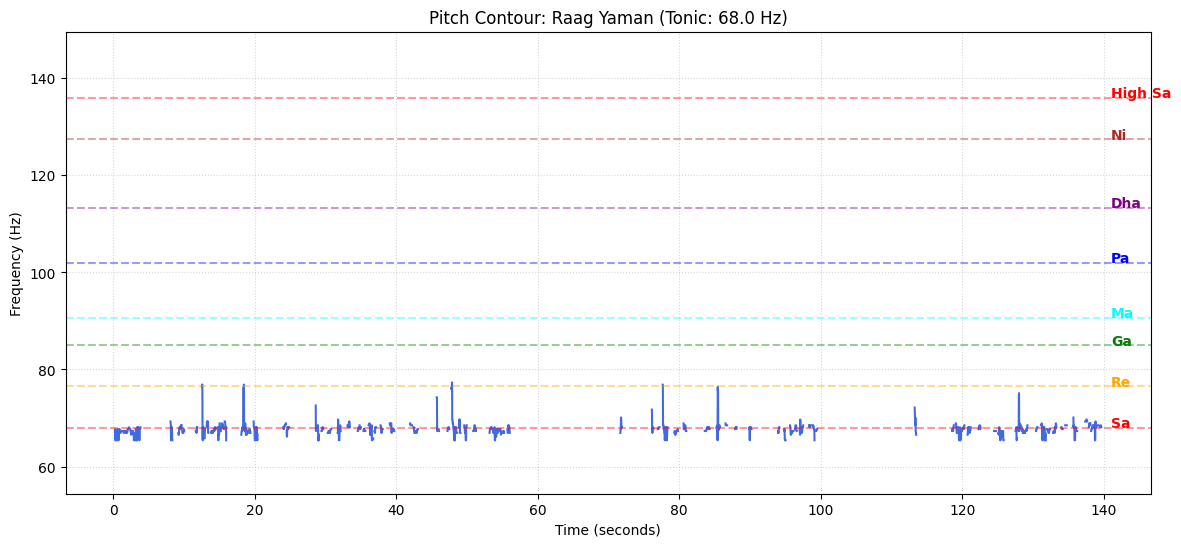

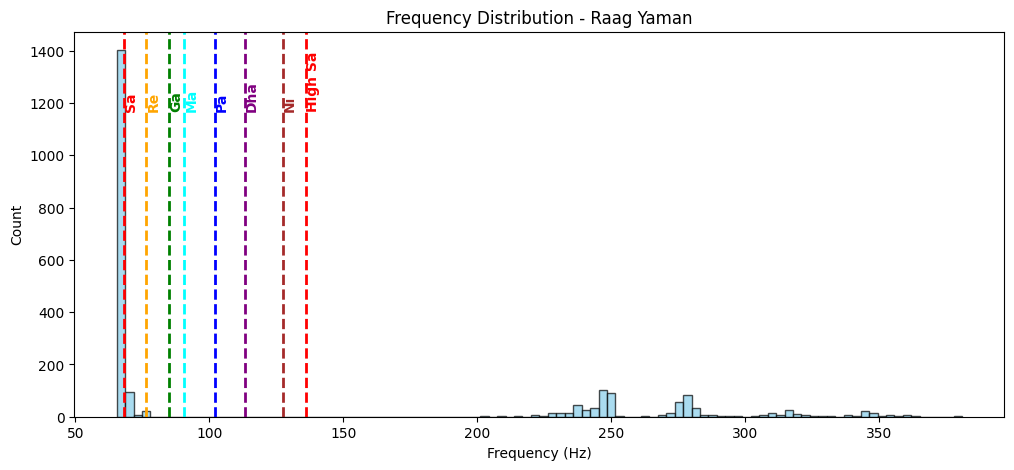

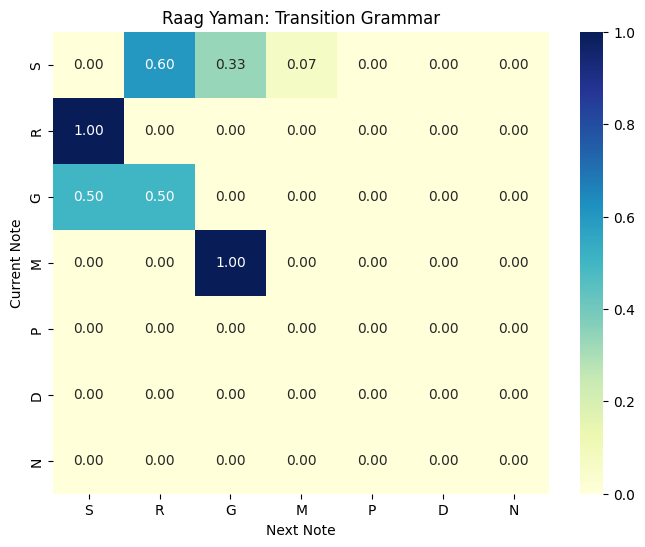

Detected Sa: 68.00 Hz
Sequence Sample: [np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('G'), np.str_('R'), np.str_('S'), np.str_('G'), np.str_('S'), np.str_('M')]

Transition Matrix:
      S    R         G         M    P    D    N
S  0.0  0.6  0.333333  0.066667  0.0  0.0  0.0
R  1.0  0.0  0.000000  0.000000  0.0  0.0  0.0
G  0.5  0.5  0.000000  0.000000  0.0  0.0  0.0
M  0.0  0.0  1.000000  0.000000  0.0  0.0  0.0
P  0.0  0.0  0.000000  0.000000  0.0  0.0  0.0
D  0.0  0.0  0.000000  0.000000  0.0  0.0  0.0
N  0.0  0.0  0.000000  0.000000  0.0  0.0  0.0


In [ ]:
import librosa
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Audio
filename = 'yaman1.wav'
y, sr = librosa.load(filename)

# 2. Extract Pitch (pYIN)
f0, voiced_flag, voiced_probs = librosa.pyin(
    y,
    fmin=librosa.note_to_hz('C2'),
    fmax=librosa.note_to_hz('C5')
)
times = librosa.times_like(f0)

# Remove NaN values
valid_f0 = f0[~np.isnan(f0)]

# 3. Detect Sa
detected_mode = scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0]
tonic_sa = float(detected_mode)

# 4. YAMAN SWARA RATIOS
swara_ratios = {
    'Sa': 1.0,
    'Re': 9/8,
    'Ga': 5/4,
    'Ma': 4/3,   # Yaman includes Ma
    'Pa': 3/2,
    'Dha': 5/3,
    'Ni': 15/8,
    'High Sa': 2.0
}

colors = ['red','orange','green','cyan','blue','purple','brown','red']

# 5. Convert to Swaras
swaras = librosa.hz_to_svara_h(valid_f0, Sa=tonic_sa)

# 6. Filter for Yaman
allowed_notes = ['S','R','G','M','P','D','N']
clean_sequence = [s for s in swaras if s in allowed_notes or s == 'M#']

# Remove duplicates
compressed_sequence = []
if len(clean_sequence) > 0:
    compressed_sequence.append(clean_sequence[0])
    for i in range(1, len(clean_sequence)):
        if clean_sequence[i] != clean_sequence[i-1]:
            compressed_sequence.append(clean_sequence[i])

# ------------------ PITCH CONTOUR ------------------
plt.figure(figsize=(14, 6))
plt.plot(times, f0, label='Singing Path', color='royalblue', linewidth=1.5)

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axhline(y=freq, color=color, linestyle='--', alpha=0.4)
    plt.text(times[-1] * 1.01, freq, name, color=color, fontweight='bold')

plt.title(f"Pitch Contour: Raag Yaman (Tonic: {tonic_sa:.1f} Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.ylim(tonic_sa * 0.8, tonic_sa * 2.2)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

# ------------------ HISTOGRAM ------------------
plt.figure(figsize=(12, 5))
plt.hist(valid_f0, bins=100, color='skyblue', alpha=0.7, edgecolor='black')

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axvline(x=freq, color=color, linestyle='--', linewidth=2)
    plt.text(freq, plt.ylim()[1]*0.8, name, rotation=90, color=color, fontweight='bold')

plt.title("Frequency Distribution - Raag Yaman")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Count")
plt.show()

# ------------------ TRANSITION MATRIX ------------------
df = pd.DataFrame(0, index=allowed_notes, columns=allowed_notes)

for i in range(len(compressed_sequence) - 1):
    current_n = compressed_sequence[i]
    next_n = compressed_sequence[i+1]
    if current_n in df.index and next_n in df.columns:
        df.loc[current_n, next_n] += 1

transition_matrix = df.div(df.sum(axis=1), axis=0).fillna(0)

# ------------------ HEATMAP ------------------
plt.figure(figsize=(8, 6))
sns.heatmap(transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Raag Yaman: Transition Grammar")
plt.xlabel("Next Note")
plt.ylabel("Current Note")
plt.show()

# ------------------ OUTPUT ------------------
print(f"Detected Sa: {tonic_sa:.2f} Hz")
print("Sequence Sample:", compressed_sequence[:15])
print("\nTransition Matrix:\n", transition_matrix)

Raag Yaman 2st audio clip

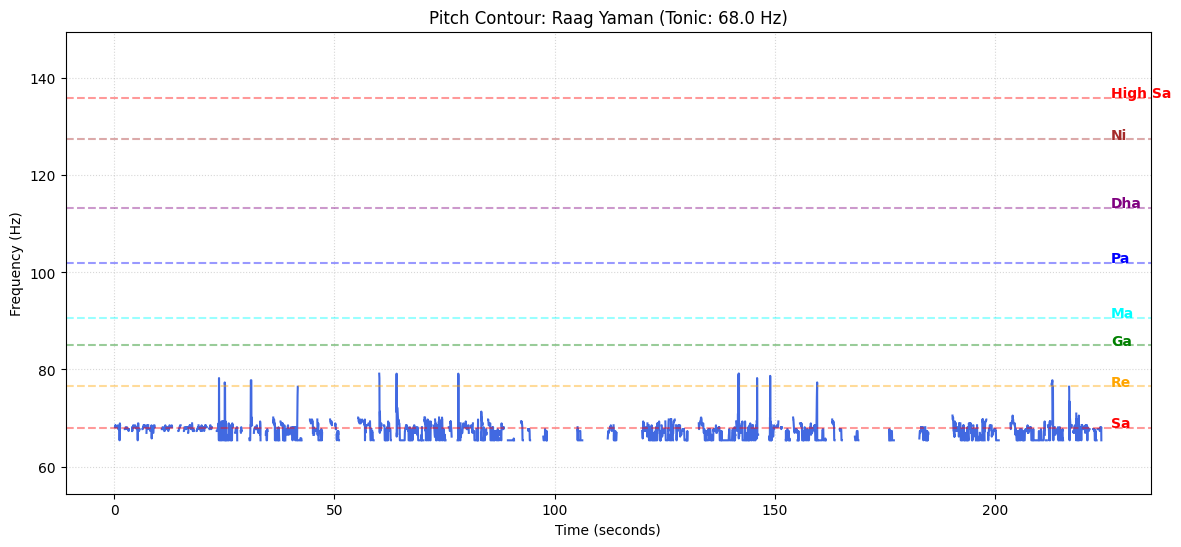

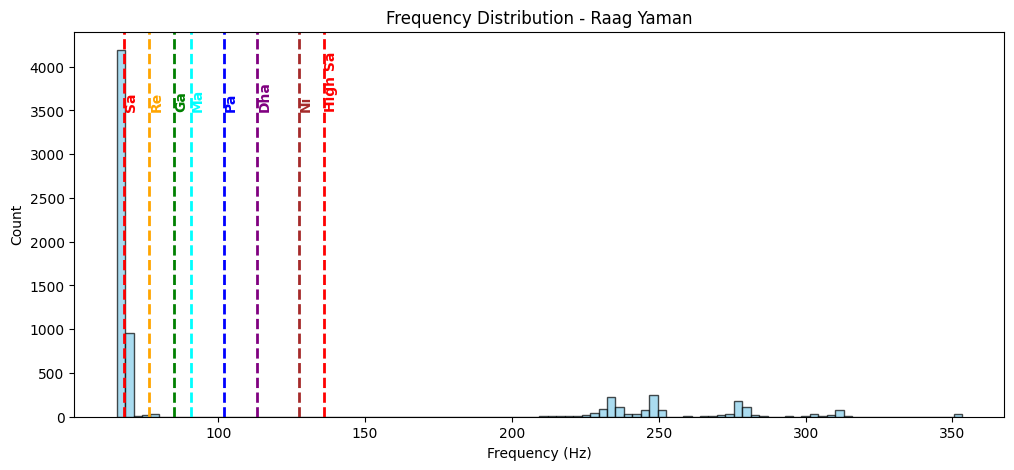

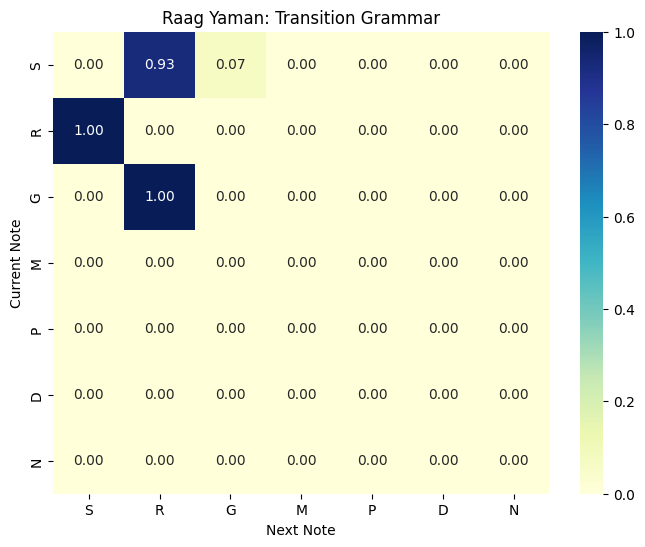

Detected Sa: 68.00 Hz
Sequence Sample: [np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('G'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R')]

Transition Matrix:
      S         R         G    M    P    D    N
S  0.0  0.928571  0.071429  0.0  0.0  0.0  0.0
R  1.0  0.000000  0.000000  0.0  0.0  0.0  0.0
G  0.0  1.000000  0.000000  0.0  0.0  0.0  0.0
M  0.0  0.000000  0.000000  0.0  0.0  0.0  0.0
P  0.0  0.000000  0.000000  0.0  0.0  0.0  0.0
D  0.0  0.000000  0.000000  0.0  0.0  0.0  0.0
N  0.0  0.000000  0.000000  0.0  0.0  0.0  0.0


In [ ]:
import librosa
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Audio
filename = 'yaman2.wav'
y, sr = librosa.load(filename)

# 2. Extract Pitch (pYIN)
f0, voiced_flag, voiced_probs = librosa.pyin(
    y,
    fmin=librosa.note_to_hz('C2'),
    fmax=librosa.note_to_hz('C5')
)
times = librosa.times_like(f0)

# Remove NaN values
valid_f0 = f0[~np.isnan(f0)]

# 3. Detect Sa
detected_mode = scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0]
tonic_sa = float(detected_mode)

# 4. YAMAN SWARA RATIOS
swara_ratios = {
    'Sa': 1.0,
    'Re': 9/8,
    'Ga': 5/4,
    'Ma': 4/3,   # Yaman includes Ma
    'Pa': 3/2,
    'Dha': 5/3,
    'Ni': 15/8,
    'High Sa': 2.0
}

colors = ['red','orange','green','cyan','blue','purple','brown','red']

# 5. Convert to Swaras
swaras = librosa.hz_to_svara_h(valid_f0, Sa=tonic_sa)

# 6. Filter for Yaman
allowed_notes = ['S','R','G','M','P','D','N']
clean_sequence = [s for s in swaras if s in allowed_notes or s == 'M#']

# Remove duplicates
compressed_sequence = []
if len(clean_sequence) > 0:
    compressed_sequence.append(clean_sequence[0])
    for i in range(1, len(clean_sequence)):
        if clean_sequence[i] != clean_sequence[i-1]:
            compressed_sequence.append(clean_sequence[i])

# ------------------ PITCH CONTOUR ------------------
plt.figure(figsize=(14, 6))
plt.plot(times, f0, label='Singing Path', color='royalblue', linewidth=1.5)

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axhline(y=freq, color=color, linestyle='--', alpha=0.4)
    plt.text(times[-1] * 1.01, freq, name, color=color, fontweight='bold')

plt.title(f"Pitch Contour: Raag Yaman (Tonic: {tonic_sa:.1f} Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.ylim(tonic_sa * 0.8, tonic_sa * 2.2)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

# ------------------ HISTOGRAM ------------------
plt.figure(figsize=(12, 5))
plt.hist(valid_f0, bins=100, color='skyblue', alpha=0.7, edgecolor='black')

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axvline(x=freq, color=color, linestyle='--', linewidth=2)
    plt.text(freq, plt.ylim()[1]*0.8, name, rotation=90, color=color, fontweight='bold')

plt.title("Frequency Distribution - Raag Yaman")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Count")
plt.show()

# ------------------ TRANSITION MATRIX ------------------
df = pd.DataFrame(0, index=allowed_notes, columns=allowed_notes)

for i in range(len(compressed_sequence) - 1):
    current_n = compressed_sequence[i]
    next_n = compressed_sequence[i+1]
    if current_n in df.index and next_n in df.columns:
        df.loc[current_n, next_n] += 1

transition_matrix = df.div(df.sum(axis=1), axis=0).fillna(0)

# ------------------ HEATMAP ------------------
plt.figure(figsize=(8, 6))
sns.heatmap(transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Raag Yaman: Transition Grammar")
plt.xlabel("Next Note")
plt.ylabel("Current Note")
plt.show()

# ------------------ OUTPUT ------------------
print(f"Detected Sa: {tonic_sa:.2f} Hz")
print("Sequence Sample:", compressed_sequence[:15])
print("\nTransition Matrix:\n", transition_matrix)

Raag Yaman 3st audio clip

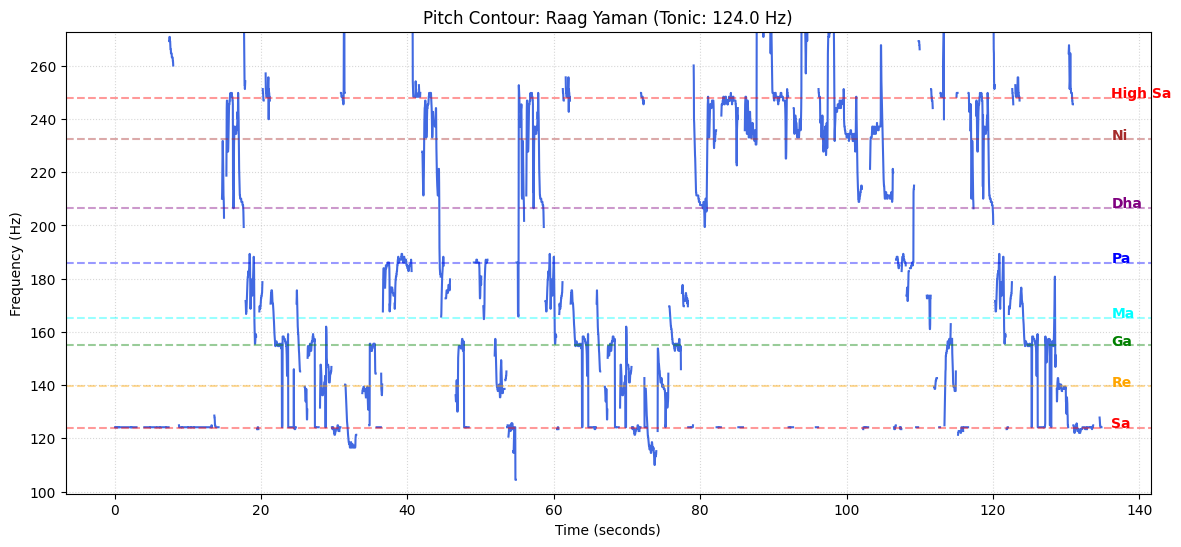

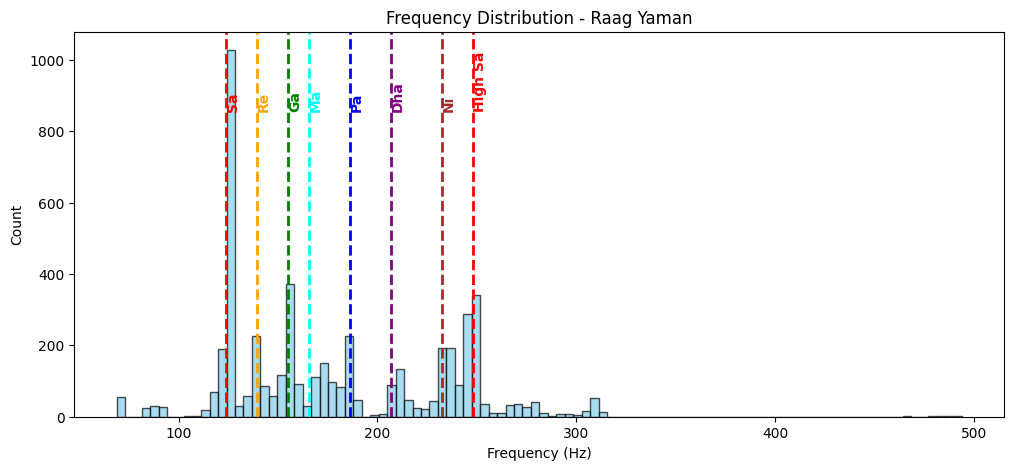

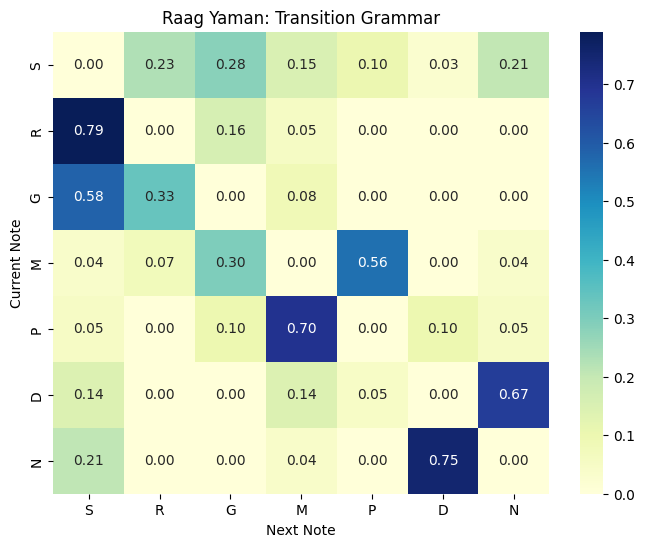

Detected Sa: 124.00 Hz
Sequence Sample: [np.str_('S'), np.str_('D'), np.str_('N'), np.str_('D'), np.str_('N'), np.str_('D'), np.str_('N'), np.str_('D'), np.str_('N'), np.str_('D'), np.str_('M'), np.str_('P'), np.str_('M'), np.str_('P'), np.str_('M')]

Transition Matrix:
           S         R         G         M         P         D         N
S  0.000000  0.230769  0.282051  0.153846  0.102564  0.025641  0.205128
R  0.789474  0.000000  0.157895  0.052632  0.000000  0.000000  0.000000
G  0.583333  0.333333  0.000000  0.083333  0.000000  0.000000  0.000000
M  0.037037  0.074074  0.296296  0.000000  0.555556  0.000000  0.037037
P  0.050000  0.000000  0.100000  0.700000  0.000000  0.100000  0.050000
D  0.142857  0.000000  0.000000  0.142857  0.047619  0.000000  0.666667
N  0.208333  0.000000  0.000000  0.041667  0.000000  0.750000  0.000000


In [ ]:
import librosa
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Audio
filename = 'yaman3.wav'
y, sr = librosa.load(filename)

# 2. Extract Pitch (pYIN)
f0, voiced_flag, voiced_probs = librosa.pyin(
    y,
    fmin=librosa.note_to_hz('C2'),
    fmax=librosa.note_to_hz('C5')
)
times = librosa.times_like(f0)

# Remove NaN values
valid_f0 = f0[~np.isnan(f0)]

# 3. Detect Sa
detected_mode = scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0]
tonic_sa = float(detected_mode)

# 4. YAMAN SWARA RATIOS
swara_ratios = {
    'Sa': 1.0,
    'Re': 9/8,
    'Ga': 5/4,
    'Ma': 4/3,   # Yaman includes Ma
    'Pa': 3/2,
    'Dha': 5/3,
    'Ni': 15/8,
    'High Sa': 2.0
}

colors = ['red','orange','green','cyan','blue','purple','brown','red']

# 5. Convert to Swaras
swaras = librosa.hz_to_svara_h(valid_f0, Sa=tonic_sa)

# 6. Filter for Yaman
allowed_notes = ['S','R','G','M','P','D','N']
clean_sequence = [s for s in swaras if s in allowed_notes or s == 'M#']

# Remove duplicates
compressed_sequence = []
if len(clean_sequence) > 0:
    compressed_sequence.append(clean_sequence[0])
    for i in range(1, len(clean_sequence)):
        if clean_sequence[i] != clean_sequence[i-1]:
            compressed_sequence.append(clean_sequence[i])

# ------------------ PITCH CONTOUR ------------------
plt.figure(figsize=(14, 6))
plt.plot(times, f0, label='Singing Path', color='royalblue', linewidth=1.5)

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axhline(y=freq, color=color, linestyle='--', alpha=0.4)
    plt.text(times[-1] * 1.01, freq, name, color=color, fontweight='bold')

plt.title(f"Pitch Contour: Raag Yaman (Tonic: {tonic_sa:.1f} Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.ylim(tonic_sa * 0.8, tonic_sa * 2.2)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

# ------------------ HISTOGRAM ------------------
plt.figure(figsize=(12, 5))
plt.hist(valid_f0, bins=100, color='skyblue', alpha=0.7, edgecolor='black')

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axvline(x=freq, color=color, linestyle='--', linewidth=2)
    plt.text(freq, plt.ylim()[1]*0.8, name, rotation=90, color=color, fontweight='bold')

plt.title("Frequency Distribution - Raag Yaman")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Count")
plt.show()

# ------------------ TRANSITION MATRIX ------------------
df = pd.DataFrame(0, index=allowed_notes, columns=allowed_notes)

for i in range(len(compressed_sequence) - 1):
    current_n = compressed_sequence[i]
    next_n = compressed_sequence[i+1]
    if current_n in df.index and next_n in df.columns:
        df.loc[current_n, next_n] += 1

transition_matrix = df.div(df.sum(axis=1), axis=0).fillna(0)

# ------------------ HEATMAP ------------------
plt.figure(figsize=(8, 6))
sns.heatmap(transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Raag Yaman: Transition Grammar")
plt.xlabel("Next Note")
plt.ylabel("Current Note")
plt.show()

# ------------------ OUTPUT ------------------
print(f"Detected Sa: {tonic_sa:.2f} Hz")
print("Sequence Sample:", compressed_sequence[:15])
print("\nTransition Matrix:\n", transition_matrix)

Raag Yaman 4th audio clip

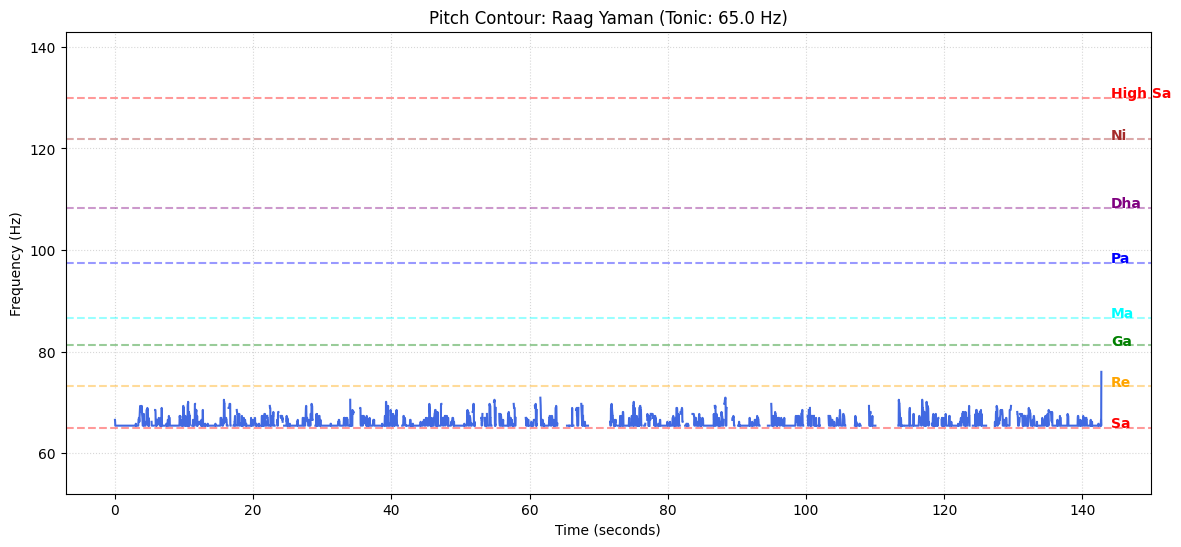

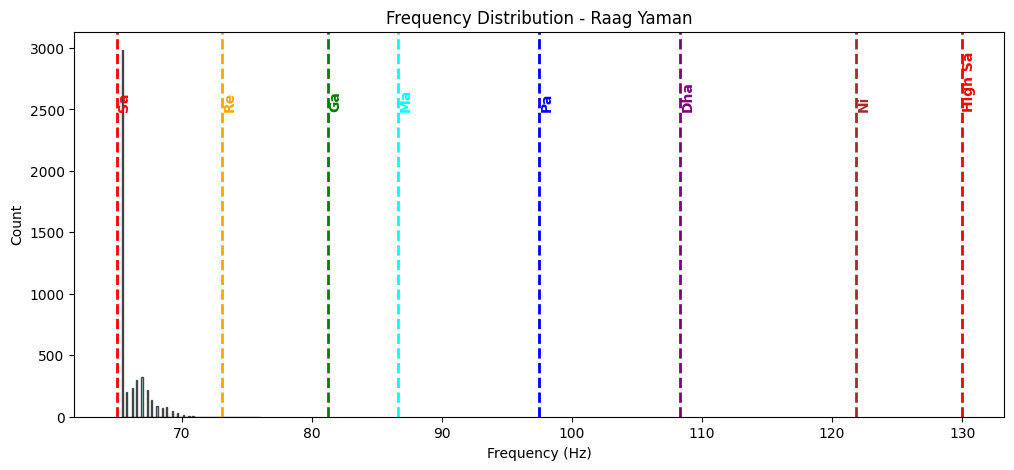

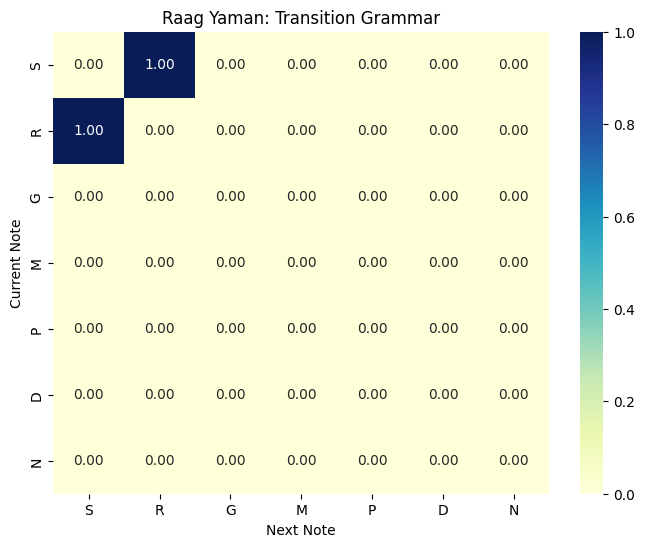

Detected Sa: 65.00 Hz
Sequence Sample: [np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S')]

Transition Matrix:
      S    R    G    M    P    D    N
S  0.0  1.0  0.0  0.0  0.0  0.0  0.0
R  1.0  0.0  0.0  0.0  0.0  0.0  0.0
G  0.0  0.0  0.0  0.0  0.0  0.0  0.0
M  0.0  0.0  0.0  0.0  0.0  0.0  0.0
P  0.0  0.0  0.0  0.0  0.0  0.0  0.0
D  0.0  0.0  0.0  0.0  0.0  0.0  0.0
N  0.0  0.0  0.0  0.0  0.0  0.0  0.0


In [ ]:
import librosa
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Audio
filename = 'yaman4.wav'
y, sr = librosa.load(filename)

# 2. Extract Pitch (pYIN)
f0, voiced_flag, voiced_probs = librosa.pyin(
    y,
    fmin=librosa.note_to_hz('C2'),
    fmax=librosa.note_to_hz('C5')
)
times = librosa.times_like(f0)

# Remove NaN values
valid_f0 = f0[~np.isnan(f0)]

# 3. Detect Sa
detected_mode = scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0]
tonic_sa = float(detected_mode)

# 4. YAMAN SWARA RATIOS
swara_ratios = {
    'Sa': 1.0,
    'Re': 9/8,
    'Ga': 5/4,
    'Ma': 4/3,   # Yaman includes Ma
    'Pa': 3/2,
    'Dha': 5/3,
    'Ni': 15/8,
    'High Sa': 2.0
}

colors = ['red','orange','green','cyan','blue','purple','brown','red']

# 5. Convert to Swaras
swaras = librosa.hz_to_svara_h(valid_f0, Sa=tonic_sa)

# 6. Filter for Yaman
allowed_notes = ['S','R','G','M','P','D','N']
clean_sequence = [s for s in swaras if s in allowed_notes or s == 'M#']

# Remove duplicates
compressed_sequence = []
if len(clean_sequence) > 0:
    compressed_sequence.append(clean_sequence[0])
    for i in range(1, len(clean_sequence)):
        if clean_sequence[i] != clean_sequence[i-1]:
            compressed_sequence.append(clean_sequence[i])

# ------------------ PITCH CONTOUR ------------------
plt.figure(figsize=(14, 6))
plt.plot(times, f0, label='Singing Path', color='royalblue', linewidth=1.5)

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axhline(y=freq, color=color, linestyle='--', alpha=0.4)
    plt.text(times[-1] * 1.01, freq, name, color=color, fontweight='bold')

plt.title(f"Pitch Contour: Raag Yaman (Tonic: {tonic_sa:.1f} Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.ylim(tonic_sa * 0.8, tonic_sa * 2.2)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

# ------------------ HISTOGRAM ------------------
plt.figure(figsize=(12, 5))
plt.hist(valid_f0, bins=100, color='skyblue', alpha=0.7, edgecolor='black')

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axvline(x=freq, color=color, linestyle='--', linewidth=2)
    plt.text(freq, plt.ylim()[1]*0.8, name, rotation=90, color=color, fontweight='bold')

plt.title("Frequency Distribution - Raag Yaman")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Count")
plt.show()

# ------------------ TRANSITION MATRIX ------------------
df = pd.DataFrame(0, index=allowed_notes, columns=allowed_notes)

for i in range(len(compressed_sequence) - 1):
    current_n = compressed_sequence[i]
    next_n = compressed_sequence[i+1]
    if current_n in df.index and next_n in df.columns:
        df.loc[current_n, next_n] += 1

transition_matrix = df.div(df.sum(axis=1), axis=0).fillna(0)

# ------------------ HEATMAP ------------------
plt.figure(figsize=(8, 6))
sns.heatmap(transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Raag Yaman: Transition Grammar")
plt.xlabel("Next Note")
plt.ylabel("Current Note")
plt.show()

# ------------------ OUTPUT ------------------
print(f"Detected Sa: {tonic_sa:.2f} Hz")
print("Sequence Sample:", compressed_sequence[:15])
print("\nTransition Matrix:\n", transition_matrix)

Raag Yaman 5th audio clip

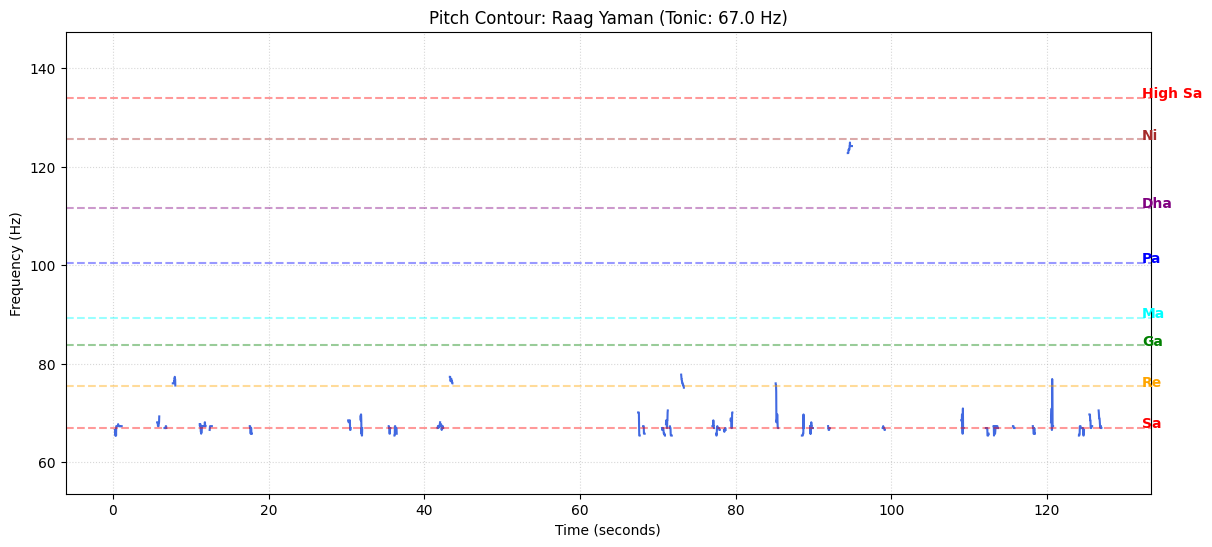

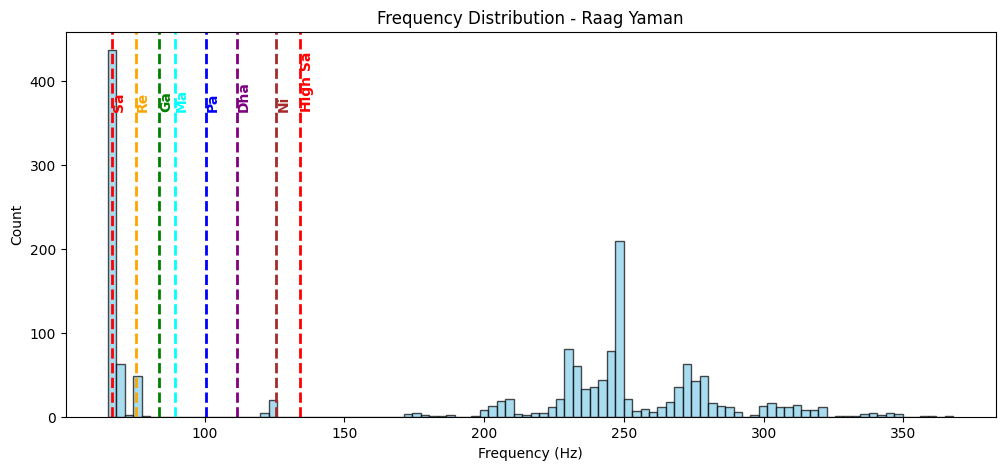

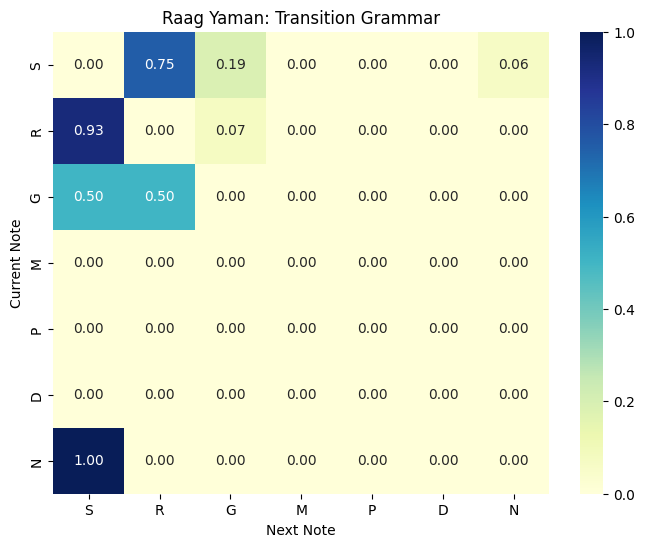

Detected Sa: 67.00 Hz
Sequence Sample: [np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('G'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('G')]

Transition Matrix:
           S     R         G    M    P    D       N
S  0.000000  0.75  0.187500  0.0  0.0  0.0  0.0625
R  0.928571  0.00  0.071429  0.0  0.0  0.0  0.0000
G  0.500000  0.50  0.000000  0.0  0.0  0.0  0.0000
M  0.000000  0.00  0.000000  0.0  0.0  0.0  0.0000
P  0.000000  0.00  0.000000  0.0  0.0  0.0  0.0000
D  0.000000  0.00  0.000000  0.0  0.0  0.0  0.0000
N  1.000000  0.00  0.000000  0.0  0.0  0.0  0.0000


In [ ]:
import librosa
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Audio
filename = 'yaman5.wav'
y, sr = librosa.load(filename)

# 2. Extract Pitch (pYIN)
f0, voiced_flag, voiced_probs = librosa.pyin(
    y,
    fmin=librosa.note_to_hz('C2'),
    fmax=librosa.note_to_hz('C5')
)
times = librosa.times_like(f0)

# Remove NaN values
valid_f0 = f0[~np.isnan(f0)]

# 3. Detect Sa
detected_mode = scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0]
tonic_sa = float(detected_mode)

# 4. YAMAN SWARA RATIOS
swara_ratios = {
    'Sa': 1.0,
    'Re': 9/8,
    'Ga': 5/4,
    'Ma': 4/3,   # Yaman includes Ma
    'Pa': 3/2,
    'Dha': 5/3,
    'Ni': 15/8,
    'High Sa': 2.0
}

colors = ['red','orange','green','cyan','blue','purple','brown','red']

# 5. Convert to Swaras
swaras = librosa.hz_to_svara_h(valid_f0, Sa=tonic_sa)

# 6. Filter for Yaman
allowed_notes = ['S','R','G','M','P','D','N']
clean_sequence = [s for s in swaras if s in allowed_notes or s == 'M#']

# Remove duplicates
compressed_sequence = []
if len(clean_sequence) > 0:
    compressed_sequence.append(clean_sequence[0])
    for i in range(1, len(clean_sequence)):
        if clean_sequence[i] != clean_sequence[i-1]:
            compressed_sequence.append(clean_sequence[i])

# ------------------ PITCH CONTOUR ------------------
plt.figure(figsize=(14, 6))
plt.plot(times, f0, label='Singing Path', color='royalblue', linewidth=1.5)

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axhline(y=freq, color=color, linestyle='--', alpha=0.4)
    plt.text(times[-1] * 1.01, freq, name, color=color, fontweight='bold')

plt.title(f"Pitch Contour: Raag Yaman (Tonic: {tonic_sa:.1f} Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.ylim(tonic_sa * 0.8, tonic_sa * 2.2)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

# ------------------ HISTOGRAM ------------------
plt.figure(figsize=(12, 5))
plt.hist(valid_f0, bins=100, color='skyblue', alpha=0.7, edgecolor='black')

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axvline(x=freq, color=color, linestyle='--', linewidth=2)
    plt.text(freq, plt.ylim()[1]*0.8, name, rotation=90, color=color, fontweight='bold')

plt.title("Frequency Distribution - Raag Yaman")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Count")
plt.show()

# ------------------ TRANSITION MATRIX ------------------
df = pd.DataFrame(0, index=allowed_notes, columns=allowed_notes)

for i in range(len(compressed_sequence) - 1):
    current_n = compressed_sequence[i]
    next_n = compressed_sequence[i+1]
    if current_n in df.index and next_n in df.columns:
        df.loc[current_n, next_n] += 1

transition_matrix = df.div(df.sum(axis=1), axis=0).fillna(0)

# ------------------ HEATMAP ------------------
plt.figure(figsize=(8, 6))
sns.heatmap(transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Raag Yaman: Transition Grammar")
plt.xlabel("Next Note")
plt.ylabel("Current Note")
plt.show()

# ------------------ OUTPUT ------------------
print(f"Detected Sa: {tonic_sa:.2f} Hz")
print("Sequence Sample:", compressed_sequence[:15])
print("\nTransition Matrix:\n", transition_matrix)

Raag Yaman 6th audio clip

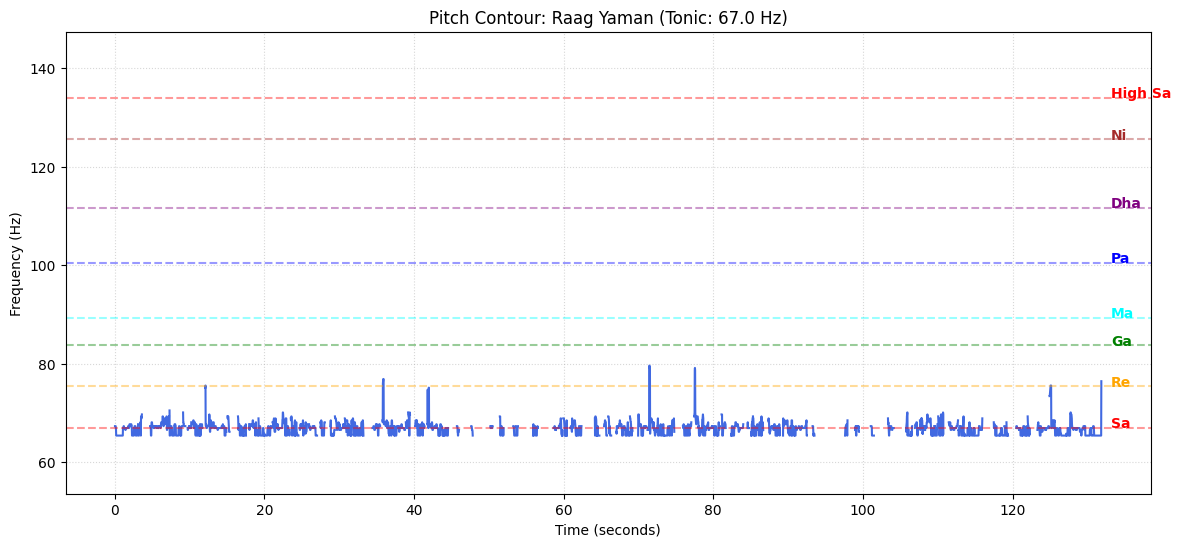

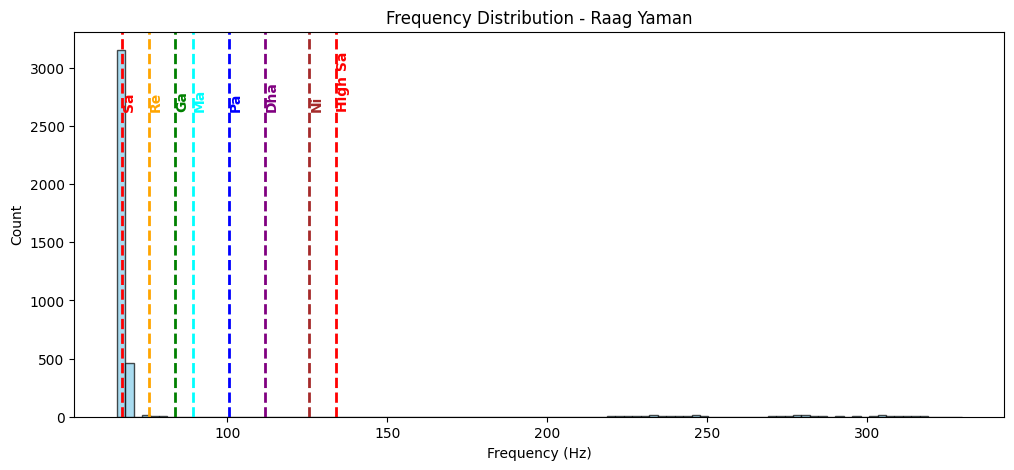

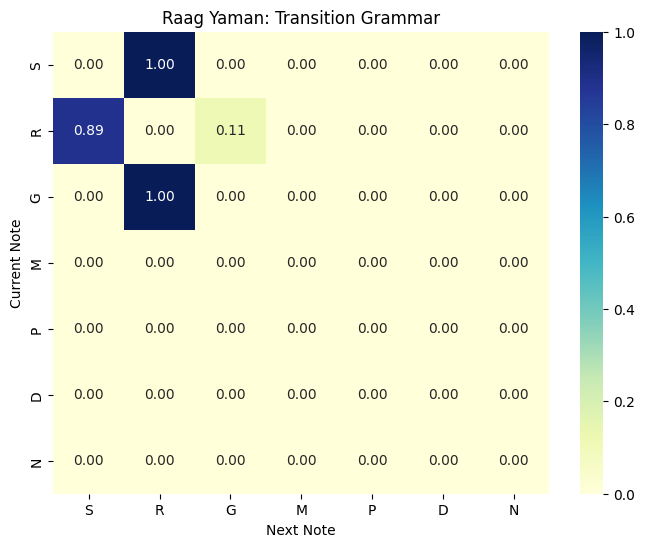

Detected Sa: 67.00 Hz
Sequence Sample: [np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('G'), np.str_('R'), np.str_('S')]

Transition Matrix:
           S    R         G    M    P    D    N
S  0.000000  1.0  0.000000  0.0  0.0  0.0  0.0
R  0.888889  0.0  0.111111  0.0  0.0  0.0  0.0
G  0.000000  1.0  0.000000  0.0  0.0  0.0  0.0
M  0.000000  0.0  0.000000  0.0  0.0  0.0  0.0
P  0.000000  0.0  0.000000  0.0  0.0  0.0  0.0
D  0.000000  0.0  0.000000  0.0  0.0  0.0  0.0
N  0.000000  0.0  0.000000  0.0  0.0  0.0  0.0


In [ ]:
import librosa
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Audio
filename = 'yaman6.wav'
y, sr = librosa.load(filename)

# 2. Extract Pitch (pYIN)
f0, voiced_flag, voiced_probs = librosa.pyin(
    y,
    fmin=librosa.note_to_hz('C2'),
    fmax=librosa.note_to_hz('C5')
)
times = librosa.times_like(f0)

# Remove NaN values
valid_f0 = f0[~np.isnan(f0)]

# 3. Detect Sa
detected_mode = scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0]
tonic_sa = float(detected_mode)

# 4. YAMAN SWARA RATIOS
swara_ratios = {
    'Sa': 1.0,
    'Re': 9/8,
    'Ga': 5/4,
    'Ma': 4/3,   # Yaman includes Ma
    'Pa': 3/2,
    'Dha': 5/3,
    'Ni': 15/8,
    'High Sa': 2.0
}

colors = ['red','orange','green','cyan','blue','purple','brown','red']

# 5. Convert to Swaras
swaras = librosa.hz_to_svara_h(valid_f0, Sa=tonic_sa)

# 6. Filter for Yaman
allowed_notes = ['S','R','G','M','P','D','N']
clean_sequence = [s for s in swaras if s in allowed_notes or s == 'M#']

# Remove duplicates
compressed_sequence = []
if len(clean_sequence) > 0:
    compressed_sequence.append(clean_sequence[0])
    for i in range(1, len(clean_sequence)):
        if clean_sequence[i] != clean_sequence[i-1]:
            compressed_sequence.append(clean_sequence[i])

# ------------------ PITCH CONTOUR ------------------
plt.figure(figsize=(14, 6))
plt.plot(times, f0, label='Singing Path', color='royalblue', linewidth=1.5)

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axhline(y=freq, color=color, linestyle='--', alpha=0.4)
    plt.text(times[-1] * 1.01, freq, name, color=color, fontweight='bold')

plt.title(f"Pitch Contour: Raag Yaman (Tonic: {tonic_sa:.1f} Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.ylim(tonic_sa * 0.8, tonic_sa * 2.2)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

# ------------------ HISTOGRAM ------------------
plt.figure(figsize=(12, 5))
plt.hist(valid_f0, bins=100, color='skyblue', alpha=0.7, edgecolor='black')

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axvline(x=freq, color=color, linestyle='--', linewidth=2)
    plt.text(freq, plt.ylim()[1]*0.8, name, rotation=90, color=color, fontweight='bold')

plt.title("Frequency Distribution - Raag Yaman")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Count")
plt.show()

# ------------------ TRANSITION MATRIX ------------------
df = pd.DataFrame(0, index=allowed_notes, columns=allowed_notes)

for i in range(len(compressed_sequence) - 1):
    current_n = compressed_sequence[i]
    next_n = compressed_sequence[i+1]
    if current_n in df.index and next_n in df.columns:
        df.loc[current_n, next_n] += 1

transition_matrix = df.div(df.sum(axis=1), axis=0).fillna(0)

# ------------------ HEATMAP ------------------
plt.figure(figsize=(8, 6))
sns.heatmap(transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Raag Yaman: Transition Grammar")
plt.xlabel("Next Note")
plt.ylabel("Current Note")
plt.show()

# ------------------ OUTPUT ------------------
print(f"Detected Sa: {tonic_sa:.2f} Hz")
print("Sequence Sample:", compressed_sequence[:15])
print("\nTransition Matrix:\n", transition_matrix)

Raag Yaman 7th audio clip

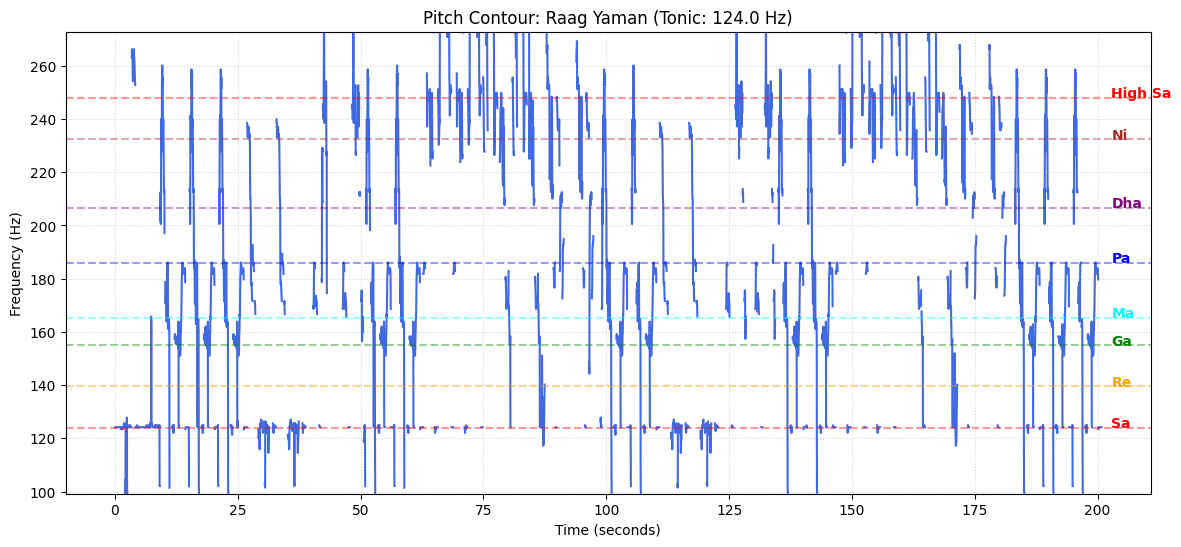

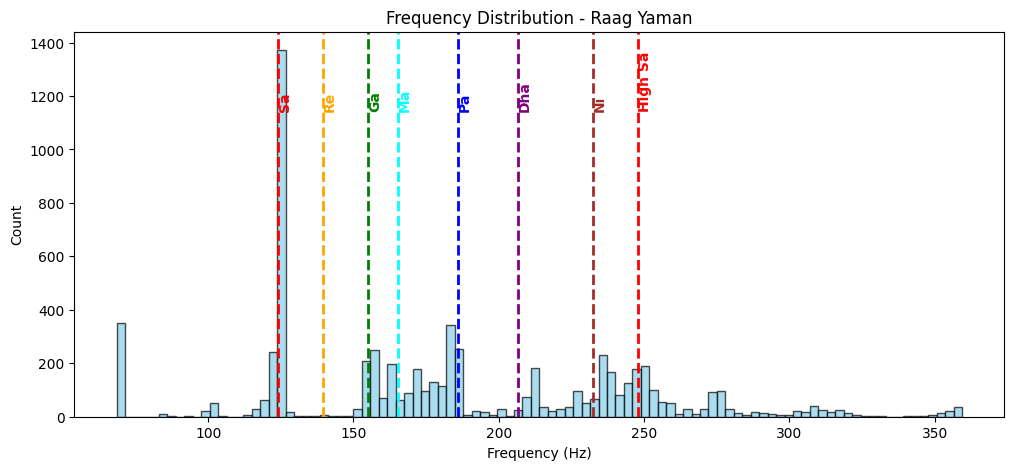

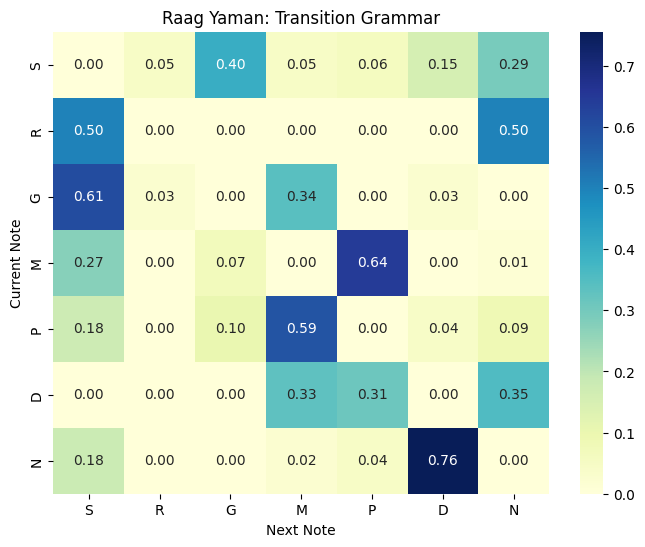

Detected Sa: 124.00 Hz
Sequence Sample: [np.str_('S'), np.str_('D'), np.str_('N'), np.str_('D'), np.str_('M'), np.str_('P'), np.str_('S'), np.str_('G'), np.str_('S'), np.str_('G'), np.str_('M'), np.str_('P'), np.str_('M'), np.str_('S'), np.str_('D')]

Transition Matrix:
           S         R         G         M         P         D         N
S  0.000000  0.046154  0.400000  0.046154  0.061538  0.153846  0.292308
R  0.500000  0.000000  0.000000  0.000000  0.000000  0.000000  0.500000
G  0.605263  0.026316  0.000000  0.342105  0.000000  0.026316  0.000000
M  0.273973  0.000000  0.068493  0.000000  0.643836  0.000000  0.013699
P  0.176471  0.000000  0.102941  0.588235  0.000000  0.044118  0.088235
D  0.000000  0.000000  0.000000  0.333333  0.312500  0.000000  0.354167
N  0.177778  0.000000  0.000000  0.022222  0.044444  0.755556  0.000000


In [ ]:
import librosa
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Audio
filename = 'yaman7.wav'
y, sr = librosa.load(filename)

# 2. Extract Pitch (pYIN)
f0, voiced_flag, voiced_probs = librosa.pyin(
    y,
    fmin=librosa.note_to_hz('C2'),
    fmax=librosa.note_to_hz('C5')
)
times = librosa.times_like(f0)

# Remove NaN values
valid_f0 = f0[~np.isnan(f0)]

# 3. Detect Sa
detected_mode = scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0]
tonic_sa = float(detected_mode)

# 4. YAMAN SWARA RATIOS
swara_ratios = {
    'Sa': 1.0,
    'Re': 9/8,
    'Ga': 5/4,
    'Ma': 4/3,   # Yaman includes Ma
    'Pa': 3/2,
    'Dha': 5/3,
    'Ni': 15/8,
    'High Sa': 2.0
}

colors = ['red','orange','green','cyan','blue','purple','brown','red']

# 5. Convert to Swaras
swaras = librosa.hz_to_svara_h(valid_f0, Sa=tonic_sa)

# 6. Filter for Yaman
allowed_notes = ['S','R','G','M','P','D','N']
clean_sequence = [s for s in swaras if s in allowed_notes or s == 'M#']

# Remove duplicates
compressed_sequence = []
if len(clean_sequence) > 0:
    compressed_sequence.append(clean_sequence[0])
    for i in range(1, len(clean_sequence)):
        if clean_sequence[i] != clean_sequence[i-1]:
            compressed_sequence.append(clean_sequence[i])

# ------------------ PITCH CONTOUR ------------------
plt.figure(figsize=(14, 6))
plt.plot(times, f0, label='Singing Path', color='royalblue', linewidth=1.5)

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axhline(y=freq, color=color, linestyle='--', alpha=0.4)
    plt.text(times[-1] * 1.01, freq, name, color=color, fontweight='bold')

plt.title(f"Pitch Contour: Raag Yaman (Tonic: {tonic_sa:.1f} Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.ylim(tonic_sa * 0.8, tonic_sa * 2.2)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

# ------------------ HISTOGRAM ------------------
plt.figure(figsize=(12, 5))
plt.hist(valid_f0, bins=100, color='skyblue', alpha=0.7, edgecolor='black')

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axvline(x=freq, color=color, linestyle='--', linewidth=2)
    plt.text(freq, plt.ylim()[1]*0.8, name, rotation=90, color=color, fontweight='bold')

plt.title("Frequency Distribution - Raag Yaman")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Count")
plt.show()

# ------------------ TRANSITION MATRIX ------------------
df = pd.DataFrame(0, index=allowed_notes, columns=allowed_notes)

for i in range(len(compressed_sequence) - 1):
    current_n = compressed_sequence[i]
    next_n = compressed_sequence[i+1]
    if current_n in df.index and next_n in df.columns:
        df.loc[current_n, next_n] += 1

transition_matrix = df.div(df.sum(axis=1), axis=0).fillna(0)

# ------------------ HEATMAP ------------------
plt.figure(figsize=(8, 6))
sns.heatmap(transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Raag Yaman: Transition Grammar")
plt.xlabel("Next Note")
plt.ylabel("Current Note")
plt.show()

# ------------------ OUTPUT ------------------
print(f"Detected Sa: {tonic_sa:.2f} Hz")
print("Sequence Sample:", compressed_sequence[:15])
print("\nTransition Matrix:\n", transition_matrix)

Raag Yaman 8th audio clip

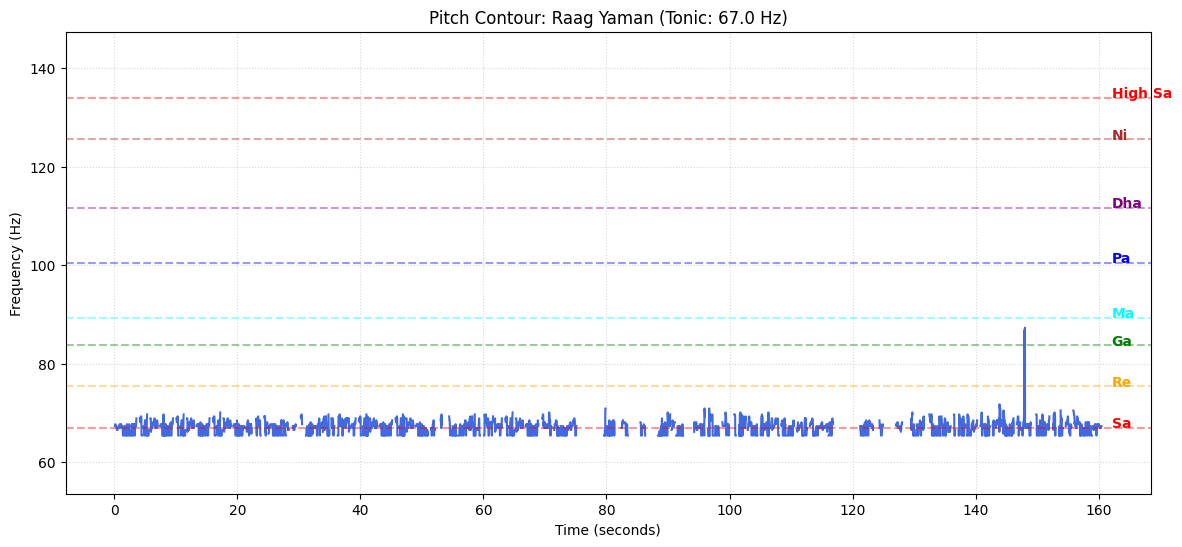

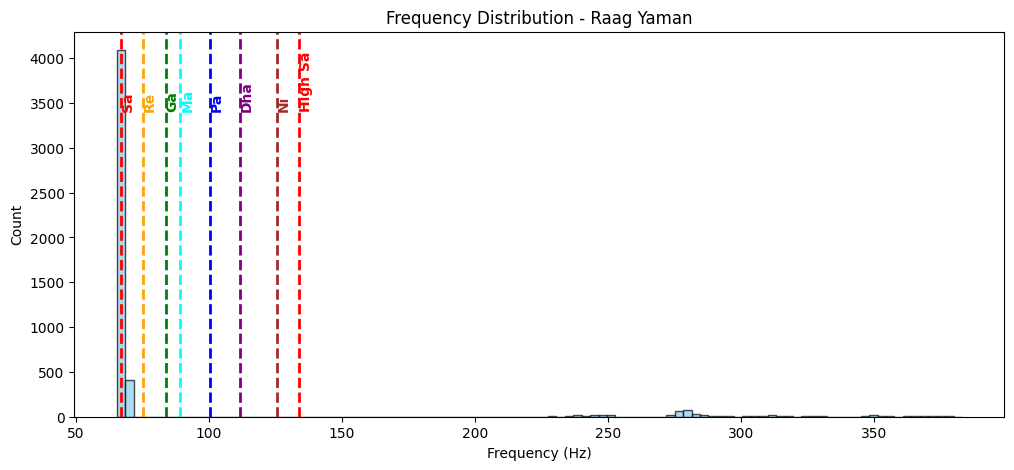

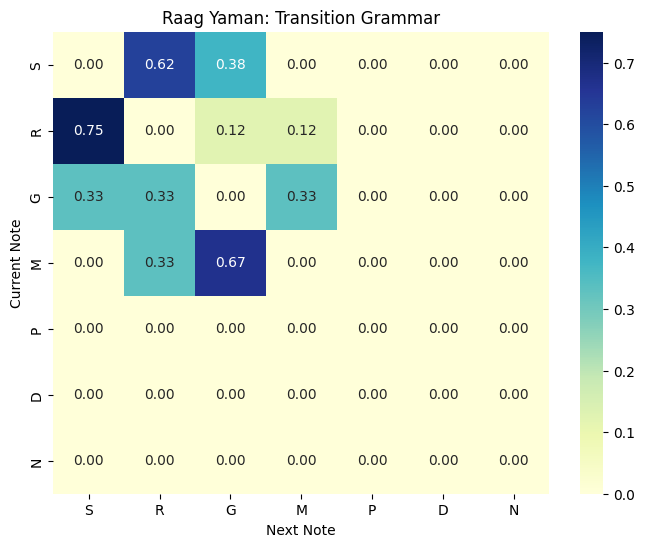

Detected Sa: 67.00 Hz
Sequence Sample: [np.str_('S'), np.str_('G'), np.str_('M'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('G'), np.str_('M'), np.str_('G'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S')]

Transition Matrix:
           S         R         G         M    P    D    N
S  0.000000  0.625000  0.375000  0.000000  0.0  0.0  0.0
R  0.750000  0.000000  0.125000  0.125000  0.0  0.0  0.0
G  0.333333  0.333333  0.000000  0.333333  0.0  0.0  0.0
M  0.000000  0.333333  0.666667  0.000000  0.0  0.0  0.0
P  0.000000  0.000000  0.000000  0.000000  0.0  0.0  0.0
D  0.000000  0.000000  0.000000  0.000000  0.0  0.0  0.0
N  0.000000  0.000000  0.000000  0.000000  0.0  0.0  0.0


In [ ]:
import librosa
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Audio
filename = 'yaman8.wav'
y, sr = librosa.load(filename)

# 2. Extract Pitch (pYIN)
f0, voiced_flag, voiced_probs = librosa.pyin(
    y,
    fmin=librosa.note_to_hz('C2'),
    fmax=librosa.note_to_hz('C5')
)
times = librosa.times_like(f0)

# Remove NaN values
valid_f0 = f0[~np.isnan(f0)]

# 3. Detect Sa
detected_mode = scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0]
tonic_sa = float(detected_mode)

# 4. YAMAN SWARA RATIOS
swara_ratios = {
    'Sa': 1.0,
    'Re': 9/8,
    'Ga': 5/4,
    'Ma': 4/3,   # Yaman includes Ma
    'Pa': 3/2,
    'Dha': 5/3,
    'Ni': 15/8,
    'High Sa': 2.0
}

colors = ['red','orange','green','cyan','blue','purple','brown','red']

# 5. Convert to Swaras
swaras = librosa.hz_to_svara_h(valid_f0, Sa=tonic_sa)

# 6. Filter for Yaman
allowed_notes = ['S','R','G','M','P','D','N']
clean_sequence = [s for s in swaras if s in allowed_notes or s == 'M#']

# Remove duplicates
compressed_sequence = []
if len(clean_sequence) > 0:
    compressed_sequence.append(clean_sequence[0])
    for i in range(1, len(clean_sequence)):
        if clean_sequence[i] != clean_sequence[i-1]:
            compressed_sequence.append(clean_sequence[i])

# ------------------ PITCH CONTOUR ------------------
plt.figure(figsize=(14, 6))
plt.plot(times, f0, label='Singing Path', color='royalblue', linewidth=1.5)

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axhline(y=freq, color=color, linestyle='--', alpha=0.4)
    plt.text(times[-1] * 1.01, freq, name, color=color, fontweight='bold')

plt.title(f"Pitch Contour: Raag Yaman (Tonic: {tonic_sa:.1f} Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.ylim(tonic_sa * 0.8, tonic_sa * 2.2)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

# ------------------ HISTOGRAM ------------------
plt.figure(figsize=(12, 5))
plt.hist(valid_f0, bins=100, color='skyblue', alpha=0.7, edgecolor='black')

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axvline(x=freq, color=color, linestyle='--', linewidth=2)
    plt.text(freq, plt.ylim()[1]*0.8, name, rotation=90, color=color, fontweight='bold')

plt.title("Frequency Distribution - Raag Yaman")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Count")
plt.show()

# ------------------ TRANSITION MATRIX ------------------
df = pd.DataFrame(0, index=allowed_notes, columns=allowed_notes)

for i in range(len(compressed_sequence) - 1):
    current_n = compressed_sequence[i]
    next_n = compressed_sequence[i+1]
    if current_n in df.index and next_n in df.columns:
        df.loc[current_n, next_n] += 1

transition_matrix = df.div(df.sum(axis=1), axis=0).fillna(0)

# ------------------ HEATMAP ------------------
plt.figure(figsize=(8, 6))
sns.heatmap(transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Raag Yaman: Transition Grammar")
plt.xlabel("Next Note")
plt.ylabel("Current Note")
plt.show()

# ------------------ OUTPUT ------------------
print(f"Detected Sa: {tonic_sa:.2f} Hz")
print("Sequence Sample:", compressed_sequence[:15])
print("\nTransition Matrix:\n", transition_matrix)

Raag Yaman 9th audio clip

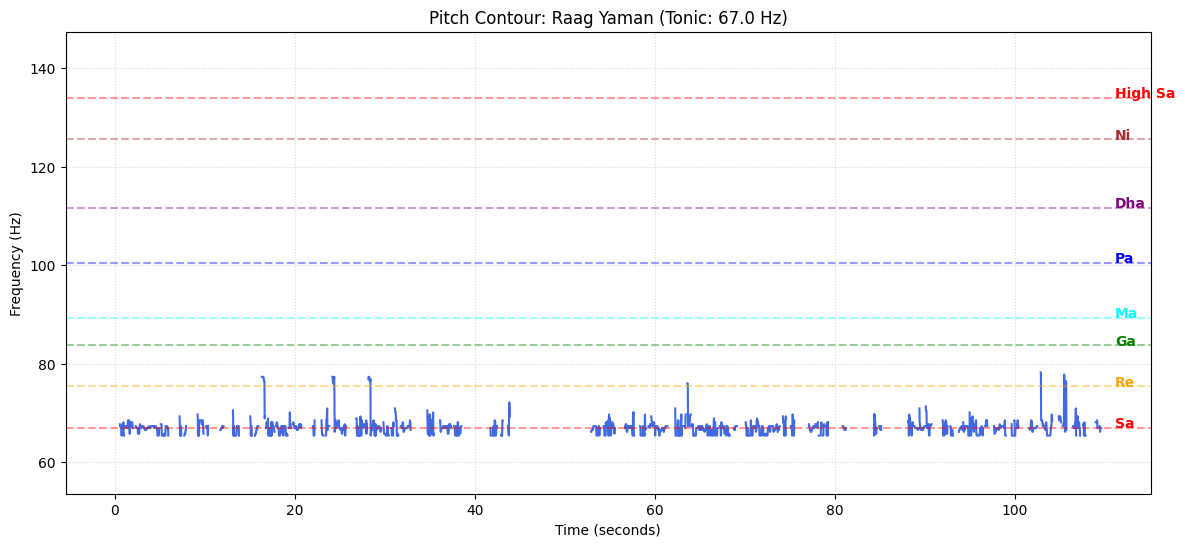

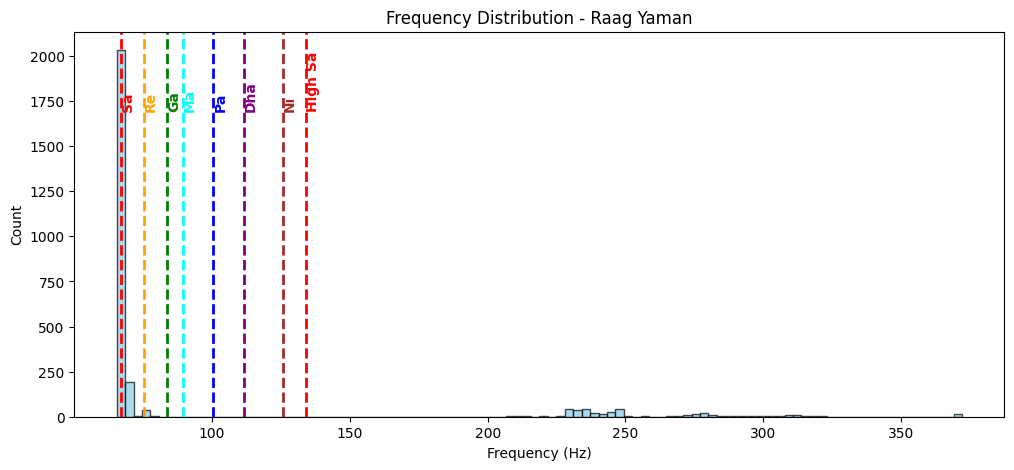

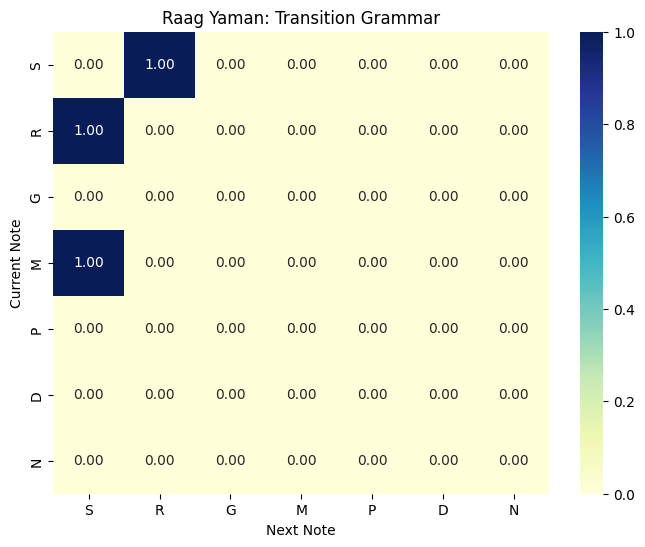

Detected Sa: 67.00 Hz
Sequence Sample: [np.str_('M'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R')]

Transition Matrix:
      S    R    G    M    P    D    N
S  0.0  1.0  0.0  0.0  0.0  0.0  0.0
R  1.0  0.0  0.0  0.0  0.0  0.0  0.0
G  0.0  0.0  0.0  0.0  0.0  0.0  0.0
M  1.0  0.0  0.0  0.0  0.0  0.0  0.0
P  0.0  0.0  0.0  0.0  0.0  0.0  0.0
D  0.0  0.0  0.0  0.0  0.0  0.0  0.0
N  0.0  0.0  0.0  0.0  0.0  0.0  0.0


In [ ]:
import librosa
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Audio
filename = 'yaman9.wav'
y, sr = librosa.load(filename)

# 2. Extract Pitch (pYIN)
f0, voiced_flag, voiced_probs = librosa.pyin(
    y,
    fmin=librosa.note_to_hz('C2'),
    fmax=librosa.note_to_hz('C5')
)
times = librosa.times_like(f0)

# Remove NaN values
valid_f0 = f0[~np.isnan(f0)]

# 3. Detect Sa
detected_mode = scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0]
tonic_sa = float(detected_mode)

# 4. YAMAN SWARA RATIOS
swara_ratios = {
    'Sa': 1.0,
    'Re': 9/8,
    'Ga': 5/4,
    'Ma': 4/3,   # Yaman includes Ma
    'Pa': 3/2,
    'Dha': 5/3,
    'Ni': 15/8,
    'High Sa': 2.0
}

colors = ['red','orange','green','cyan','blue','purple','brown','red']

# 5. Convert to Swaras
swaras = librosa.hz_to_svara_h(valid_f0, Sa=tonic_sa)

# 6. Filter for Yaman
allowed_notes = ['S','R','G','M','P','D','N']
clean_sequence = [s for s in swaras if s in allowed_notes or s == 'M#']

# Remove duplicates
compressed_sequence = []
if len(clean_sequence) > 0:
    compressed_sequence.append(clean_sequence[0])
    for i in range(1, len(clean_sequence)):
        if clean_sequence[i] != clean_sequence[i-1]:
            compressed_sequence.append(clean_sequence[i])

# ------------------ PITCH CONTOUR ------------------
plt.figure(figsize=(14, 6))
plt.plot(times, f0, label='Singing Path', color='royalblue', linewidth=1.5)

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axhline(y=freq, color=color, linestyle='--', alpha=0.4)
    plt.text(times[-1] * 1.01, freq, name, color=color, fontweight='bold')

plt.title(f"Pitch Contour: Raag Yaman (Tonic: {tonic_sa:.1f} Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.ylim(tonic_sa * 0.8, tonic_sa * 2.2)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

# ------------------ HISTOGRAM ------------------
plt.figure(figsize=(12, 5))
plt.hist(valid_f0, bins=100, color='skyblue', alpha=0.7, edgecolor='black')

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axvline(x=freq, color=color, linestyle='--', linewidth=2)
    plt.text(freq, plt.ylim()[1]*0.8, name, rotation=90, color=color, fontweight='bold')

plt.title("Frequency Distribution - Raag Yaman")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Count")
plt.show()

# ------------------ TRANSITION MATRIX ------------------
df = pd.DataFrame(0, index=allowed_notes, columns=allowed_notes)

for i in range(len(compressed_sequence) - 1):
    current_n = compressed_sequence[i]
    next_n = compressed_sequence[i+1]
    if current_n in df.index and next_n in df.columns:
        df.loc[current_n, next_n] += 1

transition_matrix = df.div(df.sum(axis=1), axis=0).fillna(0)

# ------------------ HEATMAP ------------------
plt.figure(figsize=(8, 6))
sns.heatmap(transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Raag Yaman: Transition Grammar")
plt.xlabel("Next Note")
plt.ylabel("Current Note")
plt.show()

# ------------------ OUTPUT ------------------
print(f"Detected Sa: {tonic_sa:.2f} Hz")
print("Sequence Sample:", compressed_sequence[:15])
print("\nTransition Matrix:\n", transition_matrix)

Raag Yaman 10th audio clip

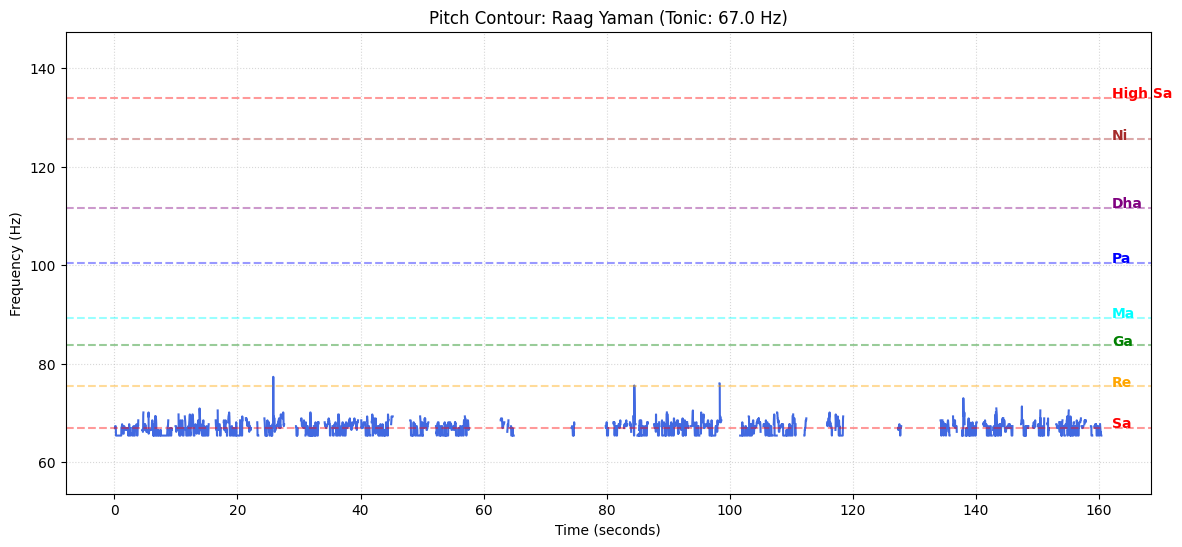

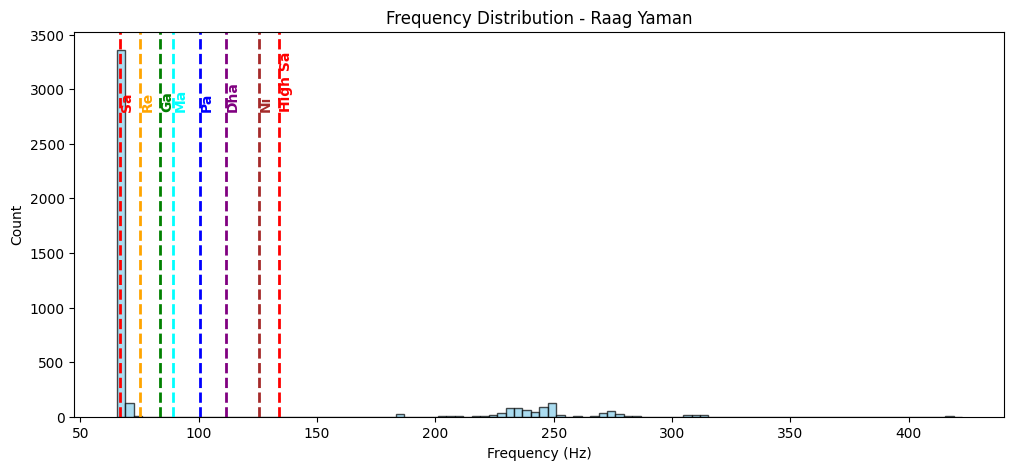

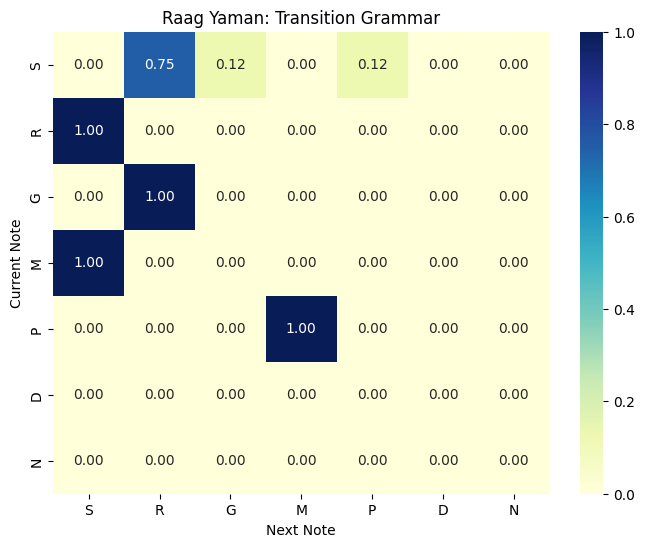

Detected Sa: 67.00 Hz
Sequence Sample: [np.str_('S'), np.str_('R'), np.str_('S'), np.str_('P'), np.str_('M'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R')]

Transition Matrix:
      S     R      G    M      P    D    N
S  0.0  0.75  0.125  0.0  0.125  0.0  0.0
R  1.0  0.00  0.000  0.0  0.000  0.0  0.0
G  0.0  1.00  0.000  0.0  0.000  0.0  0.0
M  1.0  0.00  0.000  0.0  0.000  0.0  0.0
P  0.0  0.00  0.000  1.0  0.000  0.0  0.0
D  0.0  0.00  0.000  0.0  0.000  0.0  0.0
N  0.0  0.00  0.000  0.0  0.000  0.0  0.0


In [ ]:
import librosa
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Audio
filename = 'yaman10.wav'
y, sr = librosa.load(filename)

# 2. Extract Pitch (pYIN)
f0, voiced_flag, voiced_probs = librosa.pyin(
    y,
    fmin=librosa.note_to_hz('C2'),
    fmax=librosa.note_to_hz('C5')
)
times = librosa.times_like(f0)

# Remove NaN values
valid_f0 = f0[~np.isnan(f0)]

# 3. Detect Sa
detected_mode = scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0]
tonic_sa = float(detected_mode)

# 4. YAMAN SWARA RATIOS
swara_ratios = {
    'Sa': 1.0,
    'Re': 9/8,
    'Ga': 5/4,
    'Ma': 4/3,   # Yaman includes Ma
    'Pa': 3/2,
    'Dha': 5/3,
    'Ni': 15/8,
    'High Sa': 2.0
}

colors = ['red','orange','green','cyan','blue','purple','brown','red']

# 5. Convert to Swaras
swaras = librosa.hz_to_svara_h(valid_f0, Sa=tonic_sa)

# 6. Filter for Yaman
allowed_notes = ['S','R','G','M','P','D','N']
clean_sequence = [s for s in swaras if s in allowed_notes or s == 'M#']

# Remove duplicates
compressed_sequence = []
if len(clean_sequence) > 0:
    compressed_sequence.append(clean_sequence[0])
    for i in range(1, len(clean_sequence)):
        if clean_sequence[i] != clean_sequence[i-1]:
            compressed_sequence.append(clean_sequence[i])

# ------------------ PITCH CONTOUR ------------------
plt.figure(figsize=(14, 6))
plt.plot(times, f0, label='Singing Path', color='royalblue', linewidth=1.5)

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axhline(y=freq, color=color, linestyle='--', alpha=0.4)
    plt.text(times[-1] * 1.01, freq, name, color=color, fontweight='bold')

plt.title(f"Pitch Contour: Raag Yaman (Tonic: {tonic_sa:.1f} Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.ylim(tonic_sa * 0.8, tonic_sa * 2.2)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

# ------------------ HISTOGRAM ------------------
plt.figure(figsize=(12, 5))
plt.hist(valid_f0, bins=100, color='skyblue', alpha=0.7, edgecolor='black')

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axvline(x=freq, color=color, linestyle='--', linewidth=2)
    plt.text(freq, plt.ylim()[1]*0.8, name, rotation=90, color=color, fontweight='bold')

plt.title("Frequency Distribution - Raag Yaman")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Count")
plt.show()

# ------------------ TRANSITION MATRIX ------------------
df = pd.DataFrame(0, index=allowed_notes, columns=allowed_notes)

for i in range(len(compressed_sequence) - 1):
    current_n = compressed_sequence[i]
    next_n = compressed_sequence[i+1]
    if current_n in df.index and next_n in df.columns:
        df.loc[current_n, next_n] += 1

transition_matrix = df.div(df.sum(axis=1), axis=0).fillna(0)

# ------------------ HEATMAP ------------------
plt.figure(figsize=(8, 6))
sns.heatmap(transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Raag Yaman: Transition Grammar")
plt.xlabel("Next Note")
plt.ylabel("Current Note")
plt.show()

# ------------------ OUTPUT ------------------
print(f"Detected Sa: {tonic_sa:.2f} Hz")
print("Sequence Sample:", compressed_sequence[:15])
print("\nTransition Matrix:\n", transition_matrix)

Raag Yaman 11th audio clip

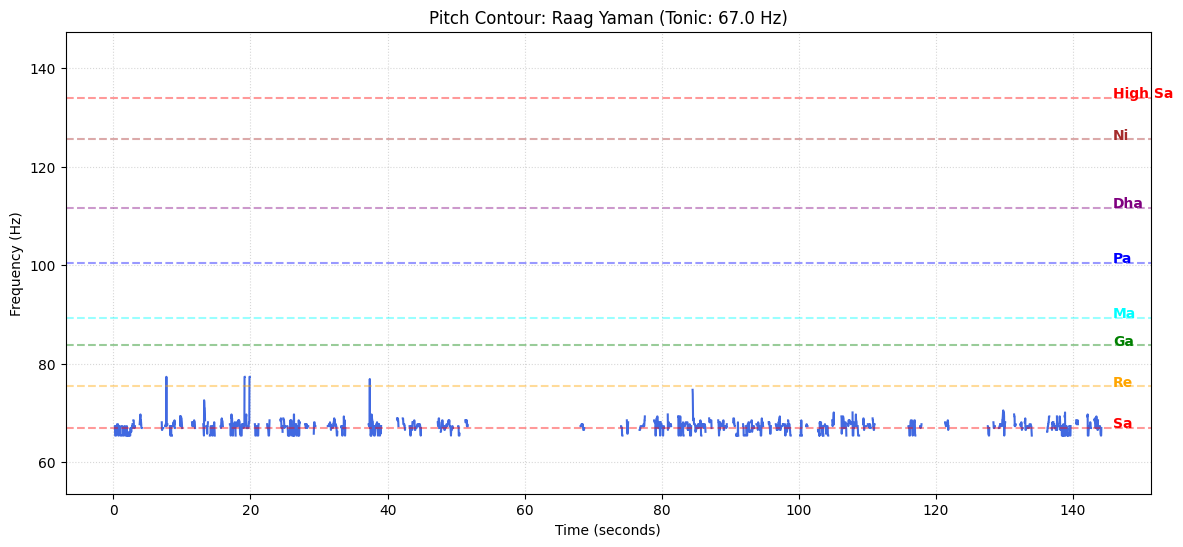

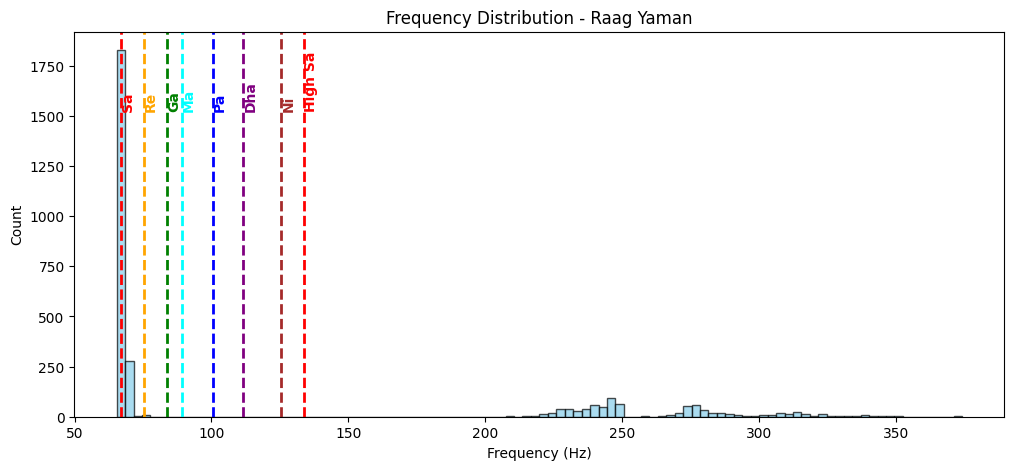

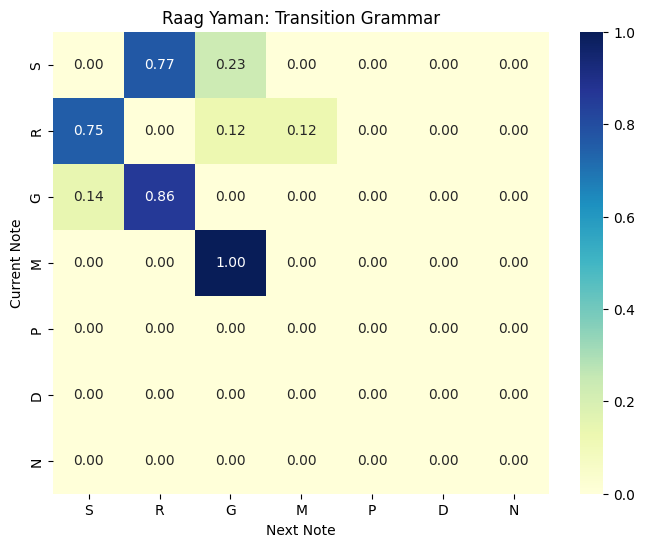

Detected Sa: 67.00 Hz
Sequence Sample: [np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('G'), np.str_('S')]

Transition Matrix:
           S         R         G      M    P    D    N
S  0.000000  0.769231  0.230769  0.000  0.0  0.0  0.0
R  0.750000  0.000000  0.125000  0.125  0.0  0.0  0.0
G  0.142857  0.857143  0.000000  0.000  0.0  0.0  0.0
M  0.000000  0.000000  1.000000  0.000  0.0  0.0  0.0
P  0.000000  0.000000  0.000000  0.000  0.0  0.0  0.0
D  0.000000  0.000000  0.000000  0.000  0.0  0.0  0.0
N  0.000000  0.000000  0.000000  0.000  0.0  0.0  0.0


In [ ]:
import librosa
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Audio
filename = 'yaman11.wav'
y, sr = librosa.load(filename)

# 2. Extract Pitch (pYIN)
f0, voiced_flag, voiced_probs = librosa.pyin(
    y,
    fmin=librosa.note_to_hz('C2'),
    fmax=librosa.note_to_hz('C5')
)
times = librosa.times_like(f0)

# Remove NaN values
valid_f0 = f0[~np.isnan(f0)]

# 3. Detect Sa
detected_mode = scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0]
tonic_sa = float(detected_mode)

# 4. YAMAN SWARA RATIOS
swara_ratios = {
    'Sa': 1.0,
    'Re': 9/8,
    'Ga': 5/4,
    'Ma': 4/3,   # Yaman includes Ma
    'Pa': 3/2,
    'Dha': 5/3,
    'Ni': 15/8,
    'High Sa': 2.0
}

colors = ['red','orange','green','cyan','blue','purple','brown','red']

# 5. Convert to Swaras
swaras = librosa.hz_to_svara_h(valid_f0, Sa=tonic_sa)

# 6. Filter for Yaman
allowed_notes = ['S','R','G','M','P','D','N']
clean_sequence = [s for s in swaras if s in allowed_notes or s == 'M#']

# Remove duplicates
compressed_sequence = []
if len(clean_sequence) > 0:
    compressed_sequence.append(clean_sequence[0])
    for i in range(1, len(clean_sequence)):
        if clean_sequence[i] != clean_sequence[i-1]:
            compressed_sequence.append(clean_sequence[i])

# ------------------ PITCH CONTOUR ------------------
plt.figure(figsize=(14, 6))
plt.plot(times, f0, label='Singing Path', color='royalblue', linewidth=1.5)

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axhline(y=freq, color=color, linestyle='--', alpha=0.4)
    plt.text(times[-1] * 1.01, freq, name, color=color, fontweight='bold')

plt.title(f"Pitch Contour: Raag Yaman (Tonic: {tonic_sa:.1f} Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.ylim(tonic_sa * 0.8, tonic_sa * 2.2)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

# ------------------ HISTOGRAM ------------------
plt.figure(figsize=(12, 5))
plt.hist(valid_f0, bins=100, color='skyblue', alpha=0.7, edgecolor='black')

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axvline(x=freq, color=color, linestyle='--', linewidth=2)
    plt.text(freq, plt.ylim()[1]*0.8, name, rotation=90, color=color, fontweight='bold')

plt.title("Frequency Distribution - Raag Yaman")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Count")
plt.show()

# ------------------ TRANSITION MATRIX ------------------
df = pd.DataFrame(0, index=allowed_notes, columns=allowed_notes)

for i in range(len(compressed_sequence) - 1):
    current_n = compressed_sequence[i]
    next_n = compressed_sequence[i+1]
    if current_n in df.index and next_n in df.columns:
        df.loc[current_n, next_n] += 1

transition_matrix = df.div(df.sum(axis=1), axis=0).fillna(0)

# ------------------ HEATMAP ------------------
plt.figure(figsize=(8, 6))
sns.heatmap(transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Raag Yaman: Transition Grammar")
plt.xlabel("Next Note")
plt.ylabel("Current Note")
plt.show()

# ------------------ OUTPUT ------------------
print(f"Detected Sa: {tonic_sa:.2f} Hz")
print("Sequence Sample:", compressed_sequence[:15])
print("\nTransition Matrix:\n", transition_matrix)

Raag Yaman 12th audio clip

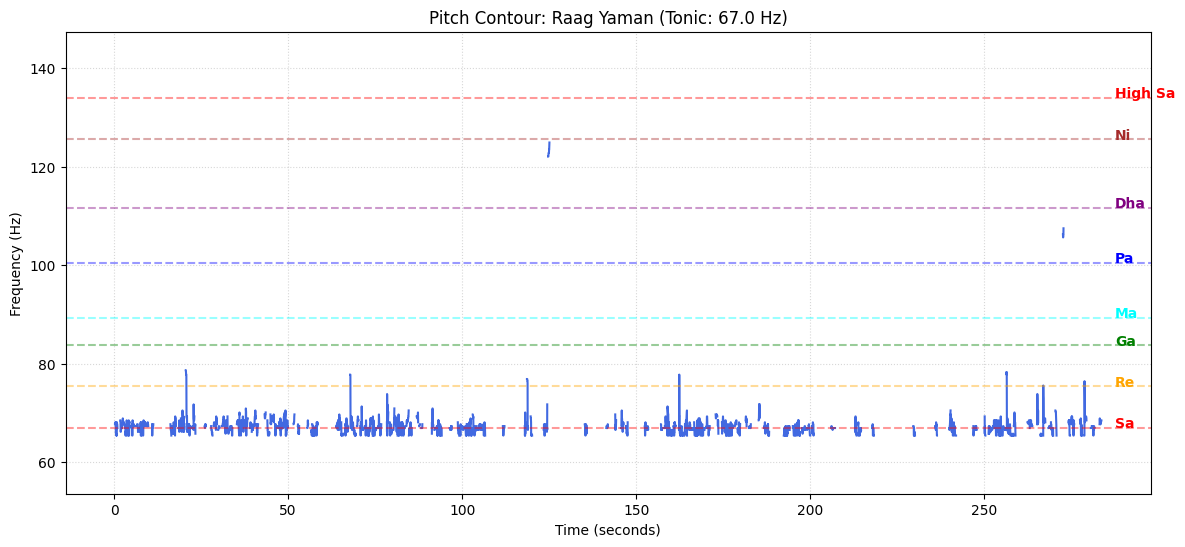

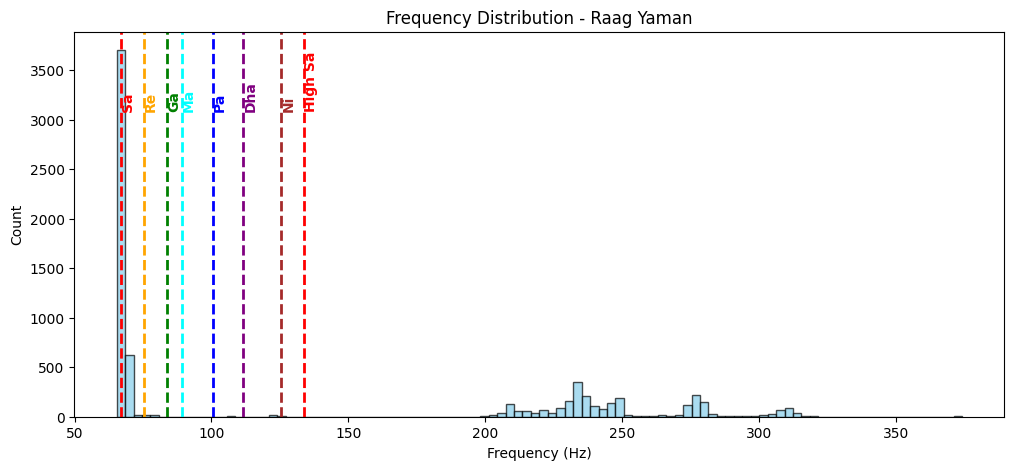

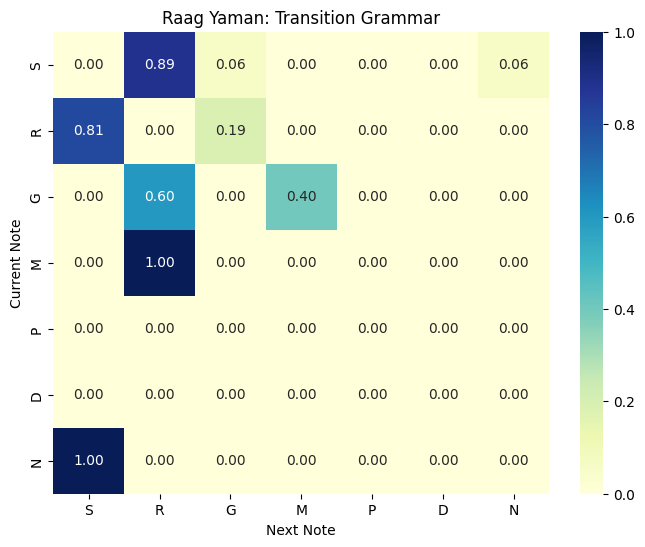

Detected Sa: 67.00 Hz
Sequence Sample: [np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('N'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('G')]

Transition Matrix:
           S         R         G    M    P    D         N
S  0.000000  0.888889  0.055556  0.0  0.0  0.0  0.055556
R  0.809524  0.000000  0.190476  0.0  0.0  0.0  0.000000
G  0.000000  0.600000  0.000000  0.4  0.0  0.0  0.000000
M  0.000000  1.000000  0.000000  0.0  0.0  0.0  0.000000
P  0.000000  0.000000  0.000000  0.0  0.0  0.0  0.000000
D  0.000000  0.000000  0.000000  0.0  0.0  0.0  0.000000
N  1.000000  0.000000  0.000000  0.0  0.0  0.0  0.000000


In [ ]:
import librosa
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Audio
filename = 'yaman12.wav'
y, sr = librosa.load(filename)

# 2. Extract Pitch (pYIN)
f0, voiced_flag, voiced_probs = librosa.pyin(
    y,
    fmin=librosa.note_to_hz('C2'),
    fmax=librosa.note_to_hz('C5')
)
times = librosa.times_like(f0)

# Remove NaN values
valid_f0 = f0[~np.isnan(f0)]

# 3. Detect Sa
detected_mode = scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0]
tonic_sa = float(detected_mode)

# 4. YAMAN SWARA RATIOS
swara_ratios = {
    'Sa': 1.0,
    'Re': 9/8,
    'Ga': 5/4,
    'Ma': 4/3,   # Yaman includes Ma
    'Pa': 3/2,
    'Dha': 5/3,
    'Ni': 15/8,
    'High Sa': 2.0
}

colors = ['red','orange','green','cyan','blue','purple','brown','red']

# 5. Convert to Swaras
swaras = librosa.hz_to_svara_h(valid_f0, Sa=tonic_sa)

# 6. Filter for Yaman
allowed_notes = ['S','R','G','M','P','D','N']
clean_sequence = [s for s in swaras if s in allowed_notes or s == 'M#']

# Remove duplicates
compressed_sequence = []
if len(clean_sequence) > 0:
    compressed_sequence.append(clean_sequence[0])
    for i in range(1, len(clean_sequence)):
        if clean_sequence[i] != clean_sequence[i-1]:
            compressed_sequence.append(clean_sequence[i])

# ------------------ PITCH CONTOUR ------------------
plt.figure(figsize=(14, 6))
plt.plot(times, f0, label='Singing Path', color='royalblue', linewidth=1.5)

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axhline(y=freq, color=color, linestyle='--', alpha=0.4)
    plt.text(times[-1] * 1.01, freq, name, color=color, fontweight='bold')

plt.title(f"Pitch Contour: Raag Yaman (Tonic: {tonic_sa:.1f} Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.ylim(tonic_sa * 0.8, tonic_sa * 2.2)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

# ------------------ HISTOGRAM ------------------
plt.figure(figsize=(12, 5))
plt.hist(valid_f0, bins=100, color='skyblue', alpha=0.7, edgecolor='black')

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axvline(x=freq, color=color, linestyle='--', linewidth=2)
    plt.text(freq, plt.ylim()[1]*0.8, name, rotation=90, color=color, fontweight='bold')

plt.title("Frequency Distribution - Raag Yaman")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Count")
plt.show()

# ------------------ TRANSITION MATRIX ------------------
df = pd.DataFrame(0, index=allowed_notes, columns=allowed_notes)

for i in range(len(compressed_sequence) - 1):
    current_n = compressed_sequence[i]
    next_n = compressed_sequence[i+1]
    if current_n in df.index and next_n in df.columns:
        df.loc[current_n, next_n] += 1

transition_matrix = df.div(df.sum(axis=1), axis=0).fillna(0)

# ------------------ HEATMAP ------------------
plt.figure(figsize=(8, 6))
sns.heatmap(transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Raag Yaman: Transition Grammar")
plt.xlabel("Next Note")
plt.ylabel("Current Note")
plt.show()

# ------------------ OUTPUT ------------------
print(f"Detected Sa: {tonic_sa:.2f} Hz")
print("Sequence Sample:", compressed_sequence[:15])
print("\nTransition Matrix:\n", transition_matrix)

Raag Yaman 13th audio clip

In [ ]:
Raag Yaman 13th audio clip

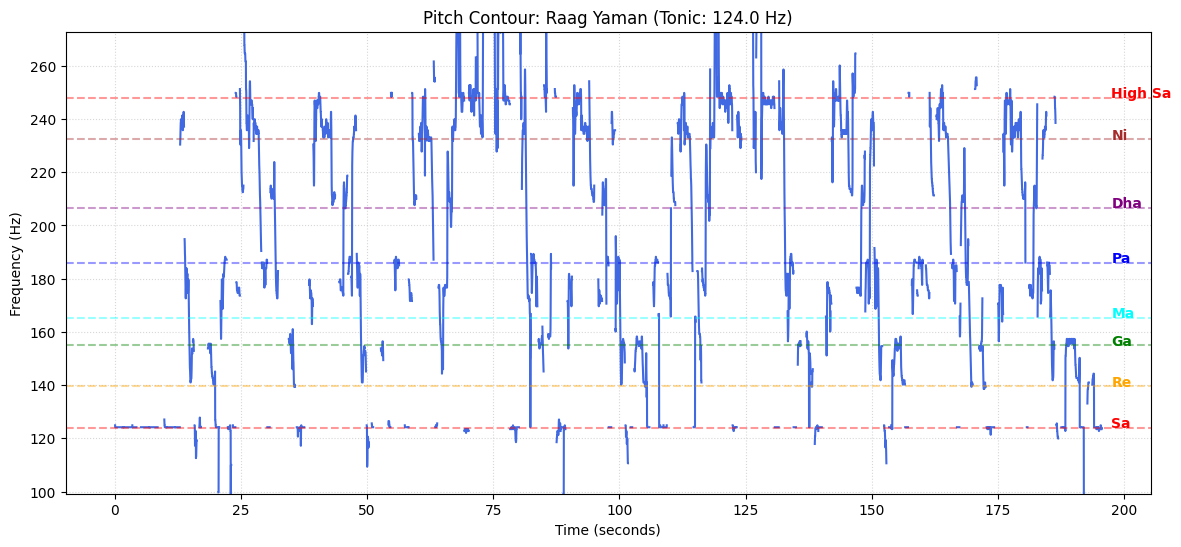

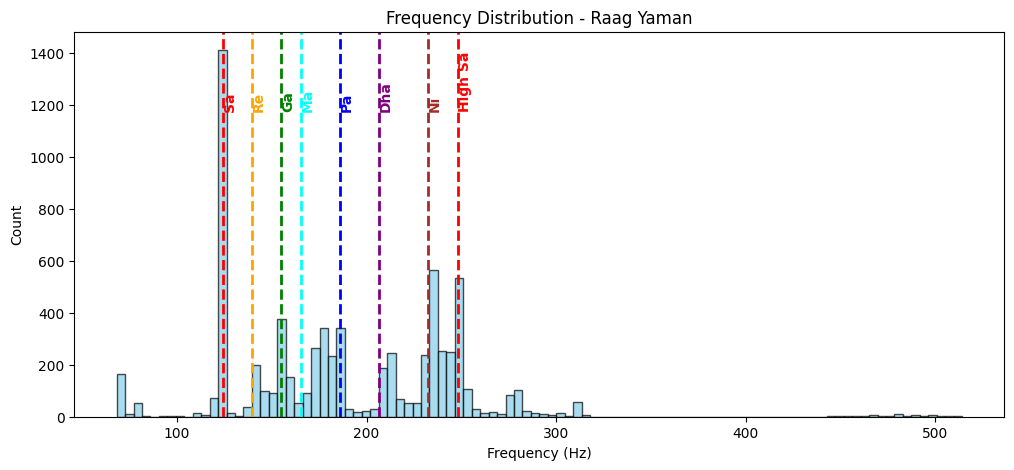

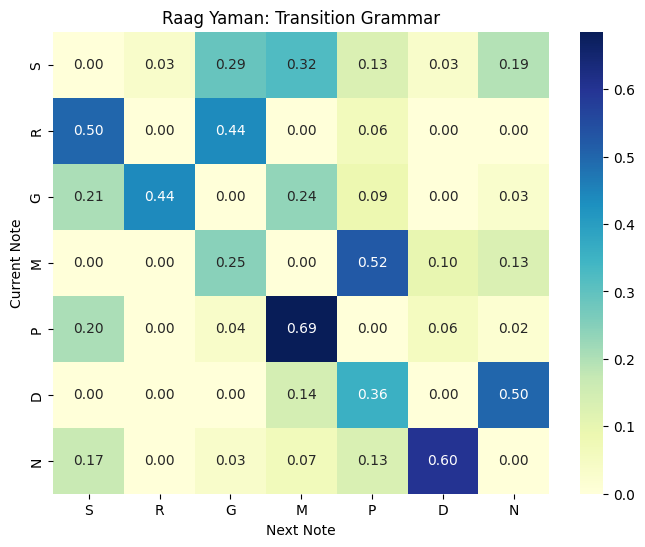

Detected Sa: 124.00 Hz
Sequence Sample: [np.str_('S'), np.str_('N'), np.str_('P'), np.str_('M'), np.str_('P'), np.str_('M'), np.str_('G'), np.str_('R'), np.str_('G'), np.str_('S'), np.str_('G'), np.str_('R'), np.str_('S'), np.str_('M'), np.str_('G')]

Transition Matrix:
           S         R         G         M         P         D         N
S  0.000000  0.032258  0.290323  0.322581  0.129032  0.032258  0.193548
R  0.500000  0.000000  0.437500  0.000000  0.062500  0.000000  0.000000
G  0.205882  0.441176  0.000000  0.235294  0.088235  0.000000  0.029412
M  0.000000  0.000000  0.245902  0.000000  0.524590  0.098361  0.131148
P  0.203704  0.000000  0.037037  0.685185  0.000000  0.055556  0.018519
D  0.000000  0.000000  0.000000  0.142857  0.357143  0.000000  0.500000
N  0.166667  0.000000  0.033333  0.066667  0.133333  0.600000  0.000000


In [ ]:
import librosa
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Audio
filename = 'yaman13.wav'
y, sr = librosa.load(filename)

# 2. Extract Pitch (pYIN)
f0, voiced_flag, voiced_probs = librosa.pyin(
    y,
    fmin=librosa.note_to_hz('C2'),
    fmax=librosa.note_to_hz('C5')
)
times = librosa.times_like(f0)

# Remove NaN values
valid_f0 = f0[~np.isnan(f0)]

# 3. Detect Sa
detected_mode = scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0]
tonic_sa = float(detected_mode)

# 4. YAMAN SWARA RATIOS
swara_ratios = {
    'Sa': 1.0,
    'Re': 9/8,
    'Ga': 5/4,
    'Ma': 4/3,   # Yaman includes Ma
    'Pa': 3/2,
    'Dha': 5/3,
    'Ni': 15/8,
    'High Sa': 2.0
}

colors = ['red','orange','green','cyan','blue','purple','brown','red']

# 5. Convert to Swaras
swaras = librosa.hz_to_svara_h(valid_f0, Sa=tonic_sa)

# 6. Filter for Yaman
allowed_notes = ['S','R','G','M','P','D','N']
clean_sequence = [s for s in swaras if s in allowed_notes or s == 'M#']

# Remove duplicates
compressed_sequence = []
if len(clean_sequence) > 0:
    compressed_sequence.append(clean_sequence[0])
    for i in range(1, len(clean_sequence)):
        if clean_sequence[i] != clean_sequence[i-1]:
            compressed_sequence.append(clean_sequence[i])

# ------------------ PITCH CONTOUR ------------------
plt.figure(figsize=(14, 6))
plt.plot(times, f0, label='Singing Path', color='royalblue', linewidth=1.5)

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axhline(y=freq, color=color, linestyle='--', alpha=0.4)
    plt.text(times[-1] * 1.01, freq, name, color=color, fontweight='bold')

plt.title(f"Pitch Contour: Raag Yaman (Tonic: {tonic_sa:.1f} Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.ylim(tonic_sa * 0.8, tonic_sa * 2.2)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

# ------------------ HISTOGRAM ------------------
plt.figure(figsize=(12, 5))
plt.hist(valid_f0, bins=100, color='skyblue', alpha=0.7, edgecolor='black')

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axvline(x=freq, color=color, linestyle='--', linewidth=2)
    plt.text(freq, plt.ylim()[1]*0.8, name, rotation=90, color=color, fontweight='bold')

plt.title("Frequency Distribution - Raag Yaman")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Count")
plt.show()

# ------------------ TRANSITION MATRIX ------------------
df = pd.DataFrame(0, index=allowed_notes, columns=allowed_notes)

for i in range(len(compressed_sequence) - 1):
    current_n = compressed_sequence[i]
    next_n = compressed_sequence[i+1]
    if current_n in df.index and next_n in df.columns:
        df.loc[current_n, next_n] += 1

transition_matrix = df.div(df.sum(axis=1), axis=0).fillna(0)

# ------------------ HEATMAP ------------------
plt.figure(figsize=(8, 6))
sns.heatmap(transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Raag Yaman: Transition Grammar")
plt.xlabel("Next Note")
plt.ylabel("Current Note")
plt.show()

# ------------------ OUTPUT ------------------
print(f"Detected Sa: {tonic_sa:.2f} Hz")
print("Sequence Sample:", compressed_sequence[:15])
print("\nTransition Matrix:\n", transition_matrix)

Raag Yaman 14th audio clip

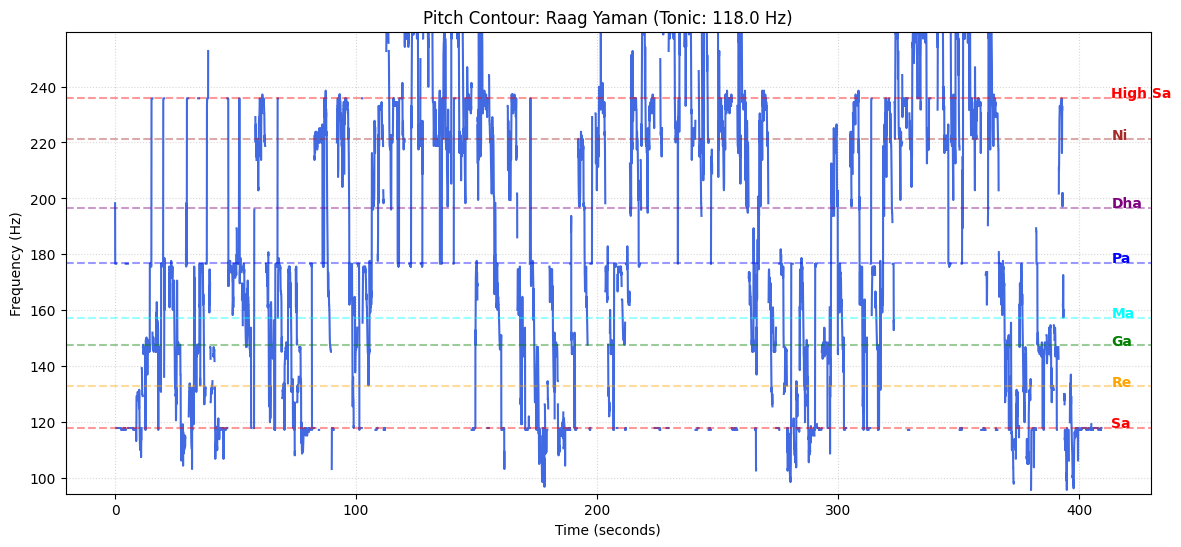

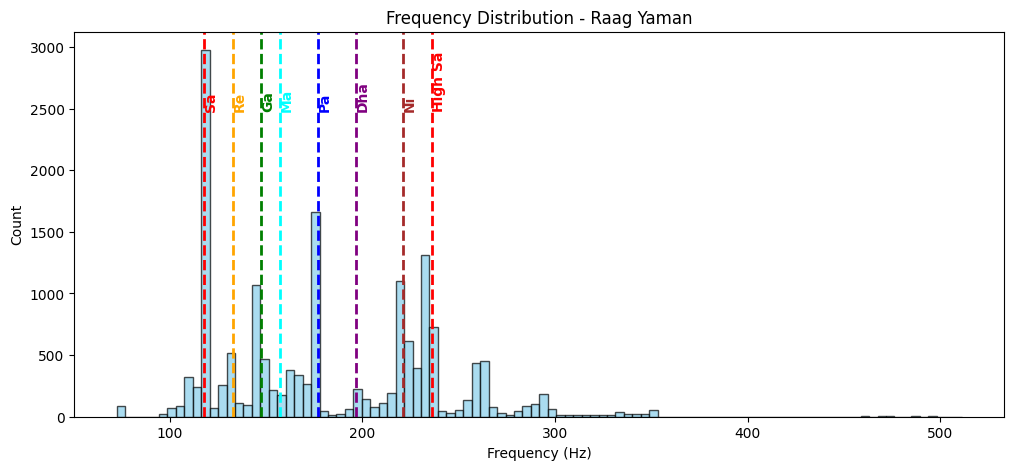

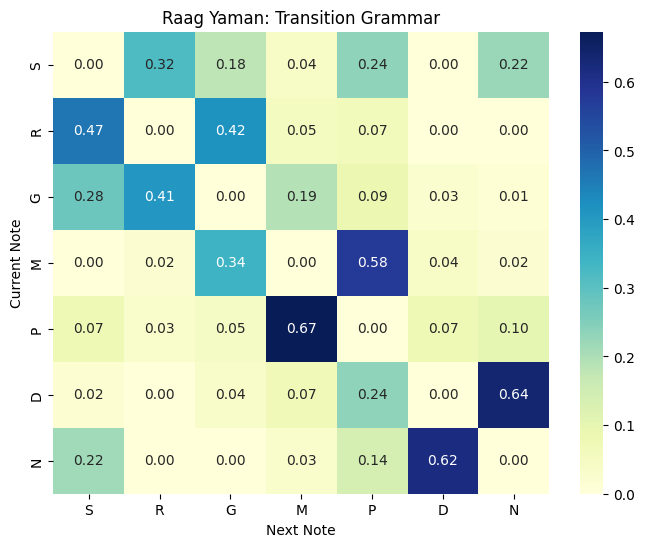

Detected Sa: 118.00 Hz
Sequence Sample: [np.str_('D'), np.str_('P'), np.str_('S'), np.str_('P'), np.str_('S'), np.str_('R'), np.str_('S'), np.str_('R'), np.str_('G'), np.str_('S'), np.str_('G'), np.str_('P'), np.str_('G'), np.str_('M'), np.str_('G')]

Transition Matrix:
           S         R         G         M         P         D         N
S  0.000000  0.319444  0.180556  0.041667  0.236111  0.000000  0.222222
R  0.466667  0.000000  0.416667  0.050000  0.066667  0.000000  0.000000
G  0.278481  0.405063  0.000000  0.189873  0.088608  0.025316  0.012658
M  0.000000  0.020202  0.343434  0.000000  0.575758  0.040404  0.020202
P  0.074766  0.028037  0.046729  0.672897  0.000000  0.074766  0.102804
D  0.018182  0.000000  0.036364  0.072727  0.236364  0.000000  0.636364
N  0.215385  0.000000  0.000000  0.030769  0.138462  0.615385  0.000000


In [ ]:
import librosa
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Audio
filename = 'yaman14.wav'
y, sr = librosa.load(filename)

# 2. Extract Pitch (pYIN)
f0, voiced_flag, voiced_probs = librosa.pyin(
    y,
    fmin=librosa.note_to_hz('C2'),
    fmax=librosa.note_to_hz('C5')
)
times = librosa.times_like(f0)

# Remove NaN values
valid_f0 = f0[~np.isnan(f0)]

# 3. Detect Sa
detected_mode = scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0]
tonic_sa = float(detected_mode)

# 4. YAMAN SWARA RATIOS
swara_ratios = {
    'Sa': 1.0,
    'Re': 9/8,
    'Ga': 5/4,
    'Ma': 4/3,   # Yaman includes Ma
    'Pa': 3/2,
    'Dha': 5/3,
    'Ni': 15/8,
    'High Sa': 2.0
}

colors = ['red','orange','green','cyan','blue','purple','brown','red']

# 5. Convert to Swaras
swaras = librosa.hz_to_svara_h(valid_f0, Sa=tonic_sa)

# 6. Filter for Yaman
allowed_notes = ['S','R','G','M','P','D','N']
clean_sequence = [s for s in swaras if s in allowed_notes or s == 'M#']

# Remove duplicates
compressed_sequence = []
if len(clean_sequence) > 0:
    compressed_sequence.append(clean_sequence[0])
    for i in range(1, len(clean_sequence)):
        if clean_sequence[i] != clean_sequence[i-1]:
            compressed_sequence.append(clean_sequence[i])

# ------------------ PITCH CONTOUR ------------------
plt.figure(figsize=(14, 6))
plt.plot(times, f0, label='Singing Path', color='royalblue', linewidth=1.5)

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axhline(y=freq, color=color, linestyle='--', alpha=0.4)
    plt.text(times[-1] * 1.01, freq, name, color=color, fontweight='bold')

plt.title(f"Pitch Contour: Raag Yaman (Tonic: {tonic_sa:.1f} Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.ylim(tonic_sa * 0.8, tonic_sa * 2.2)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

# ------------------ HISTOGRAM ------------------
plt.figure(figsize=(12, 5))
plt.hist(valid_f0, bins=100, color='skyblue', alpha=0.7, edgecolor='black')

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axvline(x=freq, color=color, linestyle='--', linewidth=2)
    plt.text(freq, plt.ylim()[1]*0.8, name, rotation=90, color=color, fontweight='bold')

plt.title("Frequency Distribution - Raag Yaman")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Count")
plt.show()

# ------------------ TRANSITION MATRIX ------------------
df = pd.DataFrame(0, index=allowed_notes, columns=allowed_notes)

for i in range(len(compressed_sequence) - 1):
    current_n = compressed_sequence[i]
    next_n = compressed_sequence[i+1]
    if current_n in df.index and next_n in df.columns:
        df.loc[current_n, next_n] += 1

transition_matrix = df.div(df.sum(axis=1), axis=0).fillna(0)

# ------------------ HEATMAP ------------------
plt.figure(figsize=(8, 6))
sns.heatmap(transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Raag Yaman: Transition Grammar")
plt.xlabel("Next Note")
plt.ylabel("Current Note")
plt.show()

# ------------------ OUTPUT ------------------
print(f"Detected Sa: {tonic_sa:.2f} Hz")
print("Sequence Sample:", compressed_sequence[:15])
print("\nTransition Matrix:\n", transition_matrix)

Raag Yaman 15th audio clip

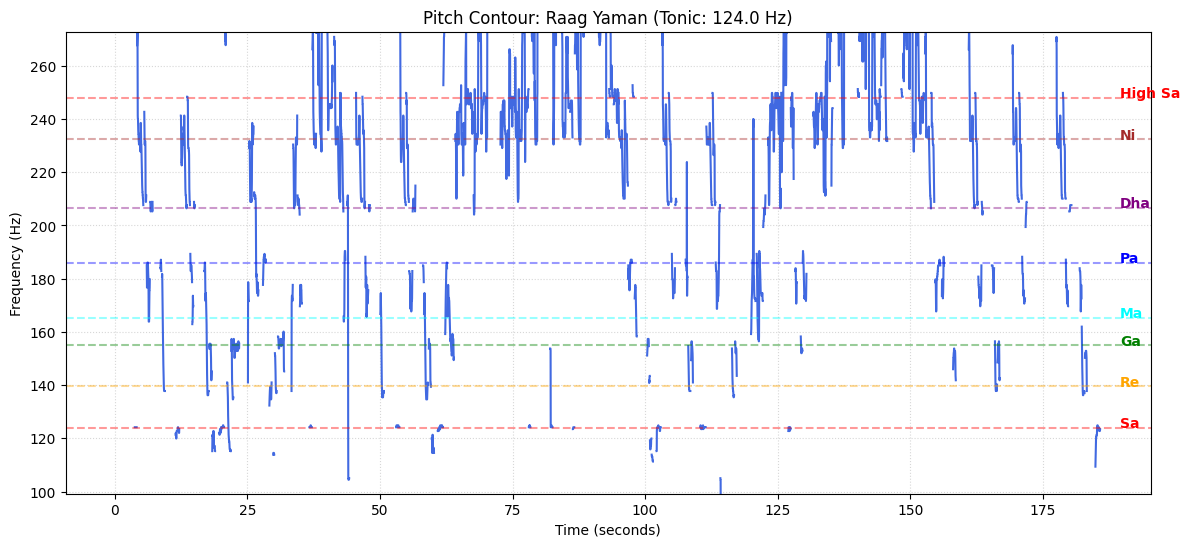

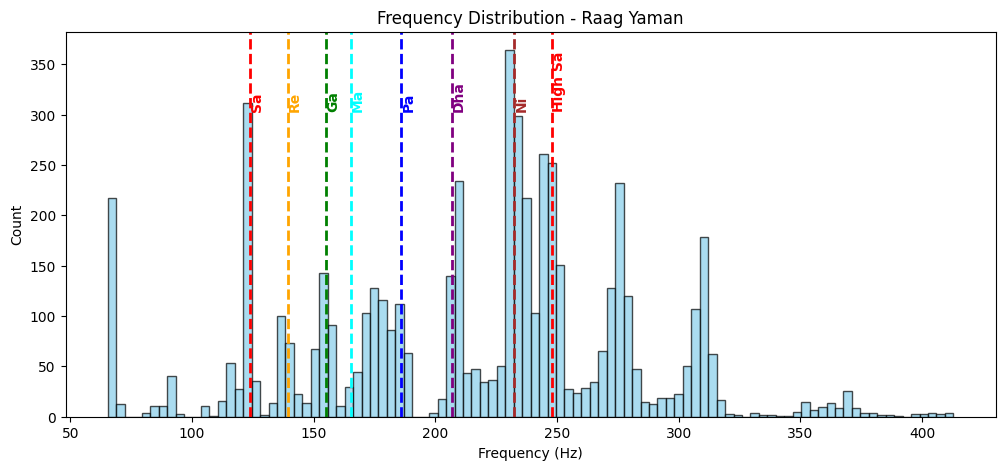

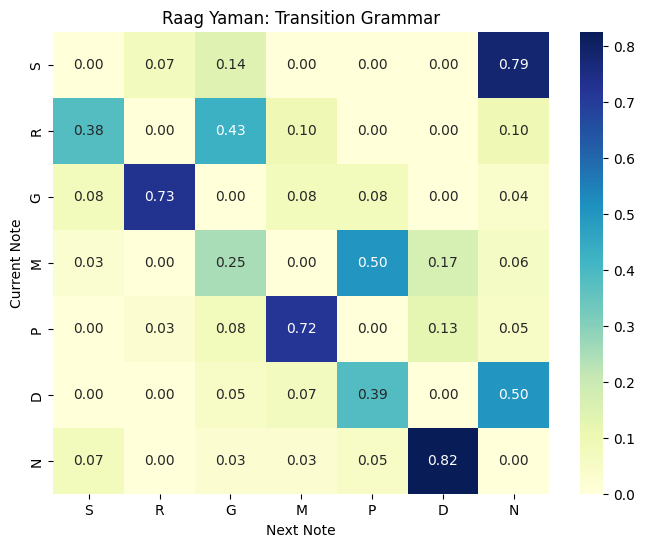

Detected Sa: 124.00 Hz
Sequence Sample: [np.str_('S'), np.str_('N'), np.str_('D'), np.str_('N'), np.str_('D'), np.str_('P'), np.str_('M'), np.str_('P'), np.str_('M'), np.str_('D'), np.str_('P'), np.str_('M'), np.str_('G'), np.str_('R'), np.str_('S')]

Transition Matrix:
           S         R         G         M         P         D         N
S  0.000000  0.071429  0.142857  0.000000  0.000000  0.000000  0.785714
R  0.380952  0.000000  0.428571  0.095238  0.000000  0.000000  0.095238
G  0.076923  0.730769  0.000000  0.076923  0.076923  0.000000  0.038462
M  0.027778  0.000000  0.250000  0.000000  0.500000  0.166667  0.055556
P  0.000000  0.025641  0.076923  0.717949  0.000000  0.128205  0.051282
D  0.000000  0.000000  0.045455  0.068182  0.386364  0.000000  0.500000
N  0.075000  0.000000  0.025000  0.025000  0.050000  0.825000  0.000000


In [ ]:
import librosa
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Audio
filename = 'yaman15.wav'
y, sr = librosa.load(filename)

# 2. Extract Pitch (pYIN)
f0, voiced_flag, voiced_probs = librosa.pyin(
    y,
    fmin=librosa.note_to_hz('C2'),
    fmax=librosa.note_to_hz('C5')
)
times = librosa.times_like(f0)

# Remove NaN values
valid_f0 = f0[~np.isnan(f0)]

# 3. Detect Sa
detected_mode = scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0]
tonic_sa = float(detected_mode)

# 4. YAMAN SWARA RATIOS
swara_ratios = {
    'Sa': 1.0,
    'Re': 9/8,
    'Ga': 5/4,
    'Ma': 4/3,   # Yaman includes Ma
    'Pa': 3/2,
    'Dha': 5/3,
    'Ni': 15/8,
    'High Sa': 2.0
}

colors = ['red','orange','green','cyan','blue','purple','brown','red']

# 5. Convert to Swaras
swaras = librosa.hz_to_svara_h(valid_f0, Sa=tonic_sa)

# 6. Filter for Yaman
allowed_notes = ['S','R','G','M','P','D','N']
clean_sequence = [s for s in swaras if s in allowed_notes or s == 'M#']

# Remove duplicates
compressed_sequence = []
if len(clean_sequence) > 0:
    compressed_sequence.append(clean_sequence[0])
    for i in range(1, len(clean_sequence)):
        if clean_sequence[i] != clean_sequence[i-1]:
            compressed_sequence.append(clean_sequence[i])

# ------------------ PITCH CONTOUR ------------------
plt.figure(figsize=(14, 6))
plt.plot(times, f0, label='Singing Path', color='royalblue', linewidth=1.5)

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axhline(y=freq, color=color, linestyle='--', alpha=0.4)
    plt.text(times[-1] * 1.01, freq, name, color=color, fontweight='bold')

plt.title(f"Pitch Contour: Raag Yaman (Tonic: {tonic_sa:.1f} Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.ylim(tonic_sa * 0.8, tonic_sa * 2.2)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

# ------------------ HISTOGRAM ------------------
plt.figure(figsize=(12, 5))
plt.hist(valid_f0, bins=100, color='skyblue', alpha=0.7, edgecolor='black')

for (name, ratio), color in zip(swara_ratios.items(), colors):
    freq = tonic_sa * ratio
    plt.axvline(x=freq, color=color, linestyle='--', linewidth=2)
    plt.text(freq, plt.ylim()[1]*0.8, name, rotation=90, color=color, fontweight='bold')

plt.title("Frequency Distribution - Raag Yaman")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Count")
plt.show()

# ------------------ TRANSITION MATRIX ------------------
df = pd.DataFrame(0, index=allowed_notes, columns=allowed_notes)

for i in range(len(compressed_sequence) - 1):
    current_n = compressed_sequence[i]
    next_n = compressed_sequence[i+1]
    if current_n in df.index and next_n in df.columns:
        df.loc[current_n, next_n] += 1

transition_matrix = df.div(df.sum(axis=1), axis=0).fillna(0)

# ------------------ HEATMAP ------------------
plt.figure(figsize=(8, 6))
sns.heatmap(transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Raag Yaman: Transition Grammar")
plt.xlabel("Next Note")
plt.ylabel("Current Note")
plt.show()

# ------------------ OUTPUT ------------------
print(f"Detected Sa: {tonic_sa:.2f} Hz")
print("Sequence Sample:", compressed_sequence[:15])
print("\nTransition Matrix:\n", transition_matrix)

In [ ]:
!pip install hmmlearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 3.6 MB/s eta 0:00:00


In [ ]:
from hmmlearn import hmm

In [ ]:
import librosa
import numpy as np
import scipy.stats

def get_swara_sequence(file_path):
    y, sr = librosa.load(file_path)

    f0, _, _ = librosa.pyin(
        y,
        fmin=librosa.note_to_hz('C2'),
        fmax=librosa.note_to_hz('C5')
    )

    valid_f0 = f0[~np.isnan(f0)]
    if len(valid_f0) == 0:
        return []

    # Detect Sa
    tonic_sa = float(scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0])

    # Convert to swaras
    swaras = librosa.hz_to_svara_h(valid_f0, Sa=tonic_sa)

    # Yaman notes
    allowed = ['S','R','G','M','P','D','N']

    clean = [s for s in swaras if s in allowed or s == 'M#']

    # Compress
    compressed = []
    if clean:
        compressed.append(clean[0])
        for i in range(1, len(clean)):
            if clean[i] != clean[i-1]:
                compressed.append(clean[i])

    return compressed

In [ ]:
import os

all_sequences = []

audio_files = [f for f in os.listdir() if f.endswith(".mp3")]

for file in audio_files:
    seq = get_swara_sequence(file)
    all_sequences.append(seq)
    print(f"Processed: {file}, length: {len(seq)}")

Processed: yaman5.mp3, length: 36
Processed: yaman4.mp3, length: 5
Processed: yaman15.mp3, length: 221
Processed: yaman13.mp3, length: 255
Processed: yaman1.mp3, length: 35
Processed: yaman14.mp3, length: 538
Processed: yaman9.mp3, length: 18
Processed: yaman7.mp3, length: 342
Processed: yaman2.mp3, length: 30
Processed: yaman10.mp3, length: 19
Processed: yaman8.mp3, length: 26
Processed: yaman3.mp3, length: 175
Processed: yaman6.mp3, length: 20
Processed: yaman12.mp3, length: 48
Processed: yaman11.mp3, length: 39


Traiing hmm model

In [ ]:
import numpy as np
from hmmlearn import hmm

# Mapping swaras to numbers
swara_to_idx = {
    'S': 0,
    'R': 1,
    'G': 2,
    'M': 3,
    'P': 4,
    'D': 5,
    'N': 6
}

# Convert sequences to numeric
X_list = [
    np.array([swara_to_idx[s] for s in seq if s in swara_to_idx]).reshape(-1, 1)
    for seq in all_sequences if len(seq) > 0
]

# Combine all
X_combined = np.concatenate(X_list)
lengths = [len(x) for x in X_list]

# Train HMM
model_yaman = hmm.CategoricalHMM(
    n_components=7,
    n_iter=200,
    random_state=42
)

print("Training model...")
model_yaman.fit(X_combined, lengths)

print("✅ Training complete")

Training model...
✅ Training complete


In [ ]:
def score_audio(file_path):
    seq = get_swara_sequence(file_path)

    if not seq:
        return -999

    numeric_seq = np.array([swara_to_idx[s] for s in seq if s in swara_to_idx]).reshape(-1,1)

    score = model_yaman.score(numeric_seq)

    # normalize
    return score / len(seq)


# -------- TEST --------
test_file = audio_files[0]   # takes first file

score = score_audio(test_file)

print(f"Score for {test_file}: {score:.3f}")

if score > -1.5:
    print(" Likely Raag Yaman")
else:
    print(" Low confidence")

Score for yaman9.wav: -0.796
✅ Likely Raag Yaman


In [ ]:
test_file = "PUT_FILE_NAME_HERE.wav"   # replace with the name of the audio clip you wnt to check if it is raag yaman or not

score = score_audio(test_file)

print(f"Score for {test_file}: {score:.3f}")

if score > -1.5:
    print("Likely Raag Yaman")
else:
    print(" Low confidence")

In [ ]:
import joblib
joblib.dump(model_yaman, "yaman_model.pkl")

['yaman_model.pkl']

In [ ]:
print(get_swara_sequence)

NameError: name 'get_swara_sequence' is not defined

In [ ]:
import joblib
joblib.dump(model_yaman, "yaman_combined.pkl")
print("✅ Saved yaman_combined.pkl")

✅ Saved yaman_combined.pkl


In [ ]:
import joblib

loaded_model = joblib.load("yaman_combined.pkl")
print("✅ PKL file loaded successfully")

✅ PKL file loaded successfully


In [ ]:
def score_audio_with_loaded_model(file_path):
    seq = get_swara_sequence(file_path)

    if not seq:
        return -999

    numeric_seq = np.array(
        [swara_to_idx[s] for s in seq if s in swara_to_idx]
    ).reshape(-1, 1)

    score = loaded_model.score(numeric_seq)

    return score / len(seq)


# CHANGE THIS TO ANY FILE YOU WANT TO TEST
test_file = "yaman9.mp3"

score = score_audio_with_loaded_model(test_file)

print(f"Score for {test_file}: {score:.3f}")

if score > -1.5:
    print("✅ Likely Raag Yaman")
else:
    print("❌ Low confidence")

Score for yaman9.mp3: -0.568
✅ Likely Raag Yaman


In [ ]:
from google.colab import files
files.download("yaman_combined.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import joblib
from hmmlearn import hmm

singer_models = {}

for i, seq in enumerate(all_sequences):
    if len(seq) < 5:
        continue

    # Convert swaras to numbers
    X_singer = np.array(
        [swara_to_idx[s] for s in seq if s in swara_to_idx]
    ).reshape(-1, 1)

    # Create HMM for this singer
    model_individual = hmm.CategoricalHMM(
        n_components=7,
        n_features=7,
        n_iter=100,
        random_state=42
    )

    # Initialize emission probabilities
    model_individual.emissionprob_ = np.full((7, 7), 1/7)

    # Train model
    model_individual.fit(X_singer)

    # Save model
    filename = f"singer_{i+1}_yaman.pkl"
    joblib.dump(model_individual, filename)

    singer_models[f"Singer_{i+1}"] = model_individual

    print(f"✅ Saved {filename}")

print("🎉 All individual models created successfully!")

✅ Saved singer_1_yaman.pkl
✅ Saved singer_2_yaman.pkl
✅ Saved singer_3_yaman.pkl


✅ Saved singer_4_yaman.pkl
✅ Saved singer_5_yaman.pkl


✅ Saved singer_6_yaman.pkl
✅ Saved singer_7_yaman.pkl
✅ Saved singer_8_yaman.pkl
✅ Saved singer_9_yaman.pkl


✅ Saved singer_10_yaman.pkl
✅ Saved singer_11_yaman.pkl
✅ Saved singer_12_yaman.pkl
✅ Saved singer_13_yaman.pkl
✅ Saved singer_14_yaman.pkl
✅ Saved singer_15_yaman.pkl
🎉 All individual models created successfully!


In [ ]:
!zip yaman_models.zip *.pkl

  adding: singer_10_yaman.pkl (deflated 47%)
  adding: singer_11_yaman.pkl (deflated 43%)
  adding: singer_12_yaman.pkl (deflated 40%)
  adding: singer_13_yaman.pkl (deflated 44%)
  adding: singer_14_yaman.pkl (deflated 44%)
  adding: singer_15_yaman.pkl (deflated 42%)
  adding: singer_1_yaman.pkl (deflated 42%)
  adding: singer_2_yaman.pkl (deflated 45%)
  adding: singer_3_yaman.pkl (deflated 39%)
  adding: singer_4_yaman.pkl (deflated 39%)
  adding: singer_5_yaman.pkl (deflated 43%)
  adding: singer_6_yaman.pkl (deflated 39%)
  adding: singer_7_yaman.pkl (deflated 44%)
  adding: singer_8_yaman.pkl (deflated 39%)
  adding: singer_9_yaman.pkl (deflated 48%)
  adding: yaman_combined.pkl (deflated 37%)


In [ ]:
from google.colab import files
files.download("yaman_models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>